tickDate - 261106
3 - 24SPXADP =        -26                - 2026-11-06 00:00:00  -      36
2 - 24NAMOT =        46                - 2026-11-06 00:00:00  -      58
8 - 24CPCE =        71                - 2026-11-06 00:00:00  -      79
4 - breadth =        709                - 2026-11-06 00:00:00  -      71
1 - 21GT50SPX =        61                - 2026-11-06 00:00:00  -      71
6 - MFI =        25                - 2026-11-06 00:00:00  -      14
7 - WMR =        -90                - 2026-11-06 00:00:00  -      -14
5 - CNN =        22                - 2026-11-06 00:00:00  -      7
9 - MA5MORE2 =        0                - 2026-11-06 00:00:00  -      0
10 - MA5MORE4 =        0                - 2026-11-06 00:00:00  -      0
11 - MA20UP =        0                - 2026-11-06 00:00:00  -      0
12 - ETF_FLOW =        9033                - 2026-11-06 00:00:00  -      179
total 12


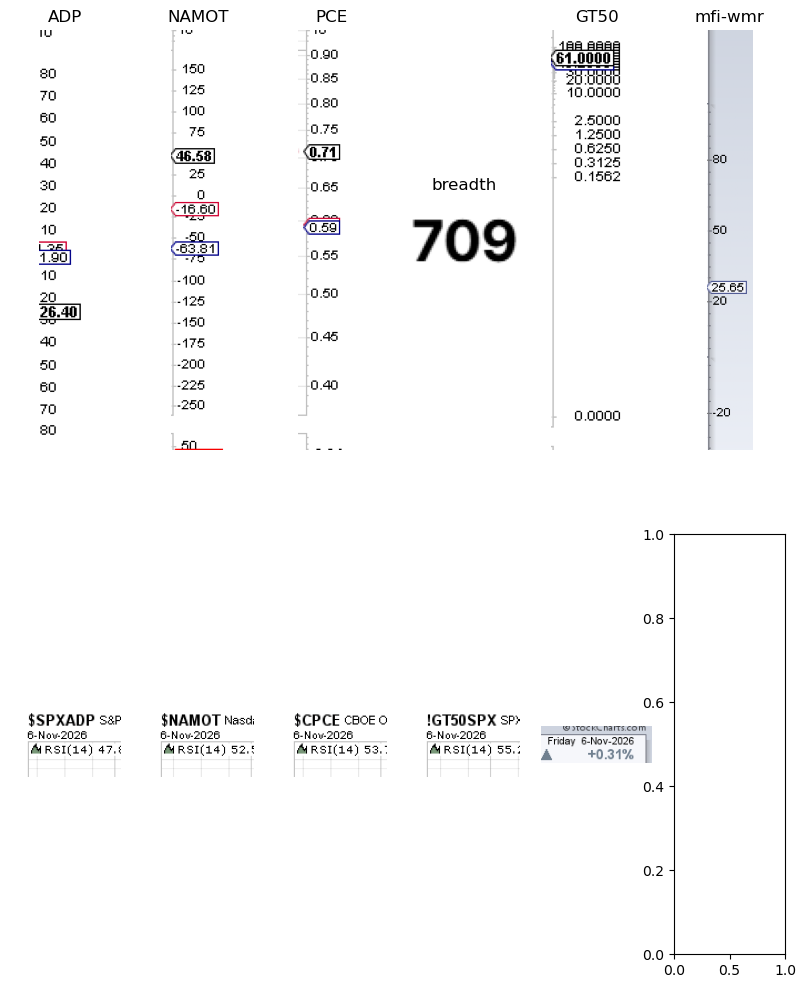

In [3]:
#!/usr/bin/python
from matplotlib import pyplot as plt
from matplotlib import image as mpimg
import datetime
from sys import argv
import mysql.connector

import configparser
config = configparser.ConfigParser()
config.read('config.ini')


def LastNlines(fname, N):
    # opening file using with() method
    # so that file get closed
    # after completing work
    with open(fname) as file:         
        # loop to read iterate
        # last n lines and print it
        for line in (file.readlines() [-N:]):
            print(line, end ='')
            
def getConnection():
    cnx = mysql.connector.connect(#         host="lookupwd-24c.cz0e64ise636.us-east-1.rds.amazonaws.com",
        
#         host="novel9.czwuawkuwlbb.us-east-1.rds.amazonaws.com",
        
#         host="lookuwd-26.cw1w0ka6m85p.us-east-1.rds.amazonaws.com",
        host=config['MySQL']['host'],
        user="novel",
        password="Test1234567",
        database="novel10",
        charset='utf8mb4'
    )
    return cnx
 
def get_ticker_date():
    # Create a datetime object representing the current date and time
    now = datetime.datetime.now()

    # Format the datetime object as a string using the strftime() method
    date_string = now.strftime("%y%m%d")

    # Print the formatted date string
    # print(date_string)
    return date_string


def get_indicator_data():
    # Connect to the database

    cnx = getConnection()

    # Create a cursor object to execute SQL queries
    cursor = cnx.cursor()

    # Execute a SQL query to retrieve data
    query = "select ti.dateAdded, ti.tickerOrder, ti.tickerValue, tiv.lowValue, tiv.highValue, tiv.direction, ti.id from " \
            "ticker_indicator ti, ticker_indicator_value tiv " \
            "where ti.tickerOrder = tiv.tickerOrder " \
            "and  ti.trend is null and  ti.tickerValue <> -999 " \
            " and DATE(ti.dateAdded) > DATE_SUB(CURDATE(), INTERVAL 6 DAY)" \
            " order by ti.dateAdded desc, ti.tickerOrder asc"

    #    "and  ti.trend is null " \

    cursor.execute(query)

    # Fetch the results of the query
    result = cursor.fetchall()

    # Print the results
    for row in result:
        dateAdded = row[0]
        tickerOrder = row[1]
        value = row[2]
        low = row[3]
        high = row[4]
        direction = row[5]
        precentValue = 0
        # if (I3 < 0, (B3 - E3) / (F3 - E3), (B3 - F3) / (E3 - F3)))
        if direction == -1:
            precentValue = (value - low) / (high - low) * 100
        if direction == 1:
            precentValue = (value - high) / (low - high) * 100

        tickerId = row[6]

#         print(str(dateAdded) + " - " + str(tickerOrder) + " = " + str(precentValue))

        sql = "UPDATE ticker_indicator SET trend = %s WHERE ID = %s;"
        cursorUpdate = cnx.cursor()
        cursorUpdate.execute(sql, (precentValue, tickerId))
        cursorUpdate.close()

    # Close the database connection
    cursor.close()

    cnx.commit()
    cnx.close()

def get_curr_ticker_value():
    
    tickerDate = get_prev_ticker_date()
    # Create a datetime object representing the current date and time
    cnx = getConnection()
    # Create a cursor object to execute SQL queries
    cursor = cnx.cursor()

#     datetime_object = datetime.strptime(tickerDate, "%y%m%d")
    # Execute a SQL query to retrieve data
    query = "select tickerOrder, tickername, tickervalue, dateAdded, trend, " \
    " IF(tickerOrder=1,5.5,IF(tickerOrder=8,3.5,IF(tickerOrder=2,3.3,IF(tickerOrder=5,8.8,tickerOrder)))) AS high_value " \
    " from ticker_indicator tiv " \
        " where DATE(tiv.dateAdded) >= %(index_date)s "  \
        " order by dateAdded desc, high_value asc; ";
    
    cursor.execute(query, {'index_date': tickerDate})
    result = cursor.fetchall()
    tickerCount = 0
    for row in result:
        print(str(row[0]) + " - " + str(row[1]) + " =        " + str(row[2]) + "                - " + str(row[3]) +
              "  -      " + str(row[4]))
        tickerCount = tickerCount + 1
    print(f"total {tickerCount}")
             
    cursor.close()
    cnx.close()



def get_prev_ticker_date():
    # Create a datetime object representing the current date and time
    cnx = getConnection()
    # Create a cursor object to execute SQL queries
    cursor = cnx.cursor()

    # Execute a SQL query to retrieve data
    query = "select max(dateAdded) from ticker_spy"

    cursor.execute(query)
    result = cursor.fetchall()
    maxId = 10000
    for i in result:
        now = i[0]
    cursor.close()
    cnx.close()

    # Format the datetime object as a string using the strftime() method
    date_string = now.strftime("%y%m%d")

    # Print the formatted date string
    # print(date_string)
    return date_string


# tickDate = '230329'
# tickDate = get_ticker_date()
tickDate = get_prev_ticker_date()
print(f"tickDate - {tickDate}")

script_path = "D:/git/panda-test/py_image" 
script_img_path = script_path + "/img/" + tickDate
arr_ticker = ['24SPXADP', '24NAMOT', '24CPCE', 'breadth', '21GT50SPX', 'MFI']
images = []

for tickerName in arr_ticker:    
    arr_idx = [0]
#     if tickerName == "MFI":
#          arr_idx = [0, 1]            
    for idx in arr_idx:  
        fileName = script_img_path + "/sc_cropped_" + tickerName + "_" +  tickDate + ".png"
#         print(fileName)
        try:
            image = mpimg.imread(fileName)
            images.append(image)
        except IOError:
             print(fileName + " not found")

arr_ticker = ['24SPXADP', '24NAMOT', '24CPCE', '21GT50SPX', 'MFI']
for tickerName in arr_ticker:    
    arr_idx = [0]        
    for idx in arr_idx:  
        fileName = script_img_path + "/sc_time_" + tickerName + "_" +  tickDate + ".png"
#         print(fileName)
        try:
            image = mpimg.imread(fileName)
            images.append(image)        
        except IOError:
             print(fileName + " not found")
    
# fig, ((ax1, ax2, ax3), (ax4, ax5, ax6)) = plt.subplots(2, 3, sharex=True, sharey=True, figsize=(10,7)) 

fig, ((ax1, ax2, ax3, ax4, ax5, ax6), (ax7, ax8, ax9, ax10, ax11, ax12)) = plt.subplots(2, 6, figsize=(10, 12)) 


try:
    ax1.imshow(images[0])
    ax1.title.set_text('ADP')
    ax1.axis('off')
    ax2.imshow(images[1])
    ax2.title.set_text('NAMOT')
    ax2.axis('off')
    ax3.imshow(images[2])
    ax3.title.set_text('PCE')
    ax3.axis('off')
    ax4.imshow(images[3])
    ax4.title.set_text('breadth')
    ax4.axis('off')
    ax5.imshow(images[4])
    ax5.title.set_text('GT50')
    ax5.axis('off')
    ax6.imshow(images[5])
    ax6.title.set_text('mfi-wmr')
    ax6.axis('off')
    ax7.imshow(images[6])
    ax7.axis('off')
    ax8.imshow(images[7])
    ax8.axis('off')
    ax9.imshow(images[8])
    ax9.axis('off')
    ax10.imshow(images[9])
    ax10.axis('off')
    ax11.imshow(images[10])
    ax11.axis('off')
except Exception as e:
    print("img not found")

def check_row_exists(tickerDate, tickerOrder):
    conn = getConnection()
    cursor = conn.cursor()
    query = "SELECT count(*) FROM ticker_indicator " \
                    " where DATE(dateAdded) >= %(index_date)s and tickerOrder = %(ticker_order)s " ;    
    cursor.execute(query, {'index_date': tickerDate, 'ticker_order': tickerOrder
                              })
    
    row_count = cursor.fetchone()[0]
    cursor.close()
    if row_count > 0:
        return True
    else:
        return False
    
# LastNlines(script_path + "/log/sc-result.txt." + tickDate, 55)

ORDER_GT50 = 1
ORDER_NAMOT = 2
ORDER_ADP = 3
ORDER_BREADTH = 4
ORDER_CNN = 5
ORDER_MFI = 6
ORDER_WMR = 7
ORDER_CPCE = 8
ORDER_MA5MORE2 = 9
ORDER_MA5MORE4 = 10
ORDER_MA20UP = 11
ORDER_ETF_FLOW = 12

def is_number_in_array(number, number_array):
    for element in number_array:
        if element == number:
            return True
    return False


def get_indicator_avg():
    # Connect to the database

    cnx = getConnection()

    # Create a cursor object to execute SQL queries
    cursor = cnx.cursor()

    # Execute a SQL query to retrieve data
    query = "select ti.dateAdded, ti.tickerOrder, ti.tickerValue, ti.id, ti.trend from " \
            "ticker_indicator ti " \
            " where DATE(ti.dateAdded) > DATE_SUB(CURDATE(), INTERVAL 6 DAY)" \
            " order by ti.dateAdded asc, ti.tickerOrder"

    # " where DATE(ti.dateAdded) > DATE_SUB(CURDATE(), INTERVAL 50 DAY)" \
    # " where DATE(ti.dateAdded) > DATE_SUB(CURDATE(), INTERVAL " + DAY_OFFSET + " DAY)" \

    cursor.execute(query)

    # Fetch the results of the query
    result = cursor.fetchall()
    lastDate = ""
    allTrend = 0
    allTrendStr = ""
    orderArray = [ORDER_ADP, ORDER_MA5MORE2, ORDER_MA5MORE4, ORDER_MA20UP, ORDER_CPCE, ORDER_ETF_FLOW]
    for row in result:
        currDate = row[0]
        currOrder = row[1]
        currTrend = row[4]
        dateAdded = str(currDate)


        if (lastDate != dateAdded and lastDate != ""):
            avgTrend = allTrend / 6
#             print(str(lastDateValue) + " - " + str(avgTrend))
#             print(allTrendStr)
            sql = "UPDATE ticker_spy SET avg = %s WHERE ticker = %s and dateAdded= %s"
            cursorUpdate = cnx.cursor()
            cursorUpdate.execute(sql, (avgTrend, "SPY", lastDateValue))
            cursorUpdate.close()
            allTrend = 0
            allTrendStr = ""
        if is_number_in_array(currOrder, orderArray ) != True:
            allTrendStr = allTrendStr + ",  " + str(currOrder) + " - " + str(currTrend) + " - " + dateAdded
            allTrend = allTrend + currTrend
        lastDate = dateAdded
        lastDateValue = currDate

    # allTrendStr = allTrendStr + ",  " + str(currOrder) + " - " + str(currTrend) + " - " + dateAdded
    # allTrend = allTrend + currTrend

    avgTrend = allTrend / 6
    print(str(lastDateValue) + " - " + str(avgTrend))
    print(allTrendStr)
    sql = "UPDATE ticker_spy SET avg = %s WHERE ticker = %s and dateAdded= %s"
    cursorUpdate = cnx.cursor()
    cursorUpdate.execute(sql, (avgTrend, "SPY", lastDateValue))
    cursorUpdate.close()

    # Close the database connection
    cursor.close()

    cnx.commit()
    cnx.close()

def updateTickerValue(my_list):   

    tickerDate = get_prev_ticker_date()
    cnx = getConnection()
    for mapping in my_list:    
        name = mapping['name']
        tickerOrder = mapping['order']
        tickerValue = mapping['value']
        lvb_exist = check_row_exists(tickerDate, tickerOrder)
        if lvb_exist:
            cursor = cnx.cursor()                
            query = "update ticker_indicator  " \
                      " set tickerValue = %(ticker_value)s, trend = null,  diff = null, diffFlag = null " \
                        " where DATE(dateAdded) >= %(index_date)s and tickerOrder = %(ticker_order)s " ;    
            cursor.execute(query, {
                'ticker_value': tickerValue, 'index_date': tickerDate, 'ticker_order': tickerOrder
                                  })
            cursor.close()
        else:
            cursor = cnx.cursor()                
            query = "insert into ticker_indicator  " \
                      " (dateSys, dateAdded, tickerOrder, tickerValue, tickerName) values( %(index_date)s, " \
             " %(index_date)s, %(ticker_order)s,  %(ticker_value)s,  %(ticker_name)s) " ;    
            cursor.execute(query, {
                'ticker_value': tickerValue, 'index_date': tickerDate, 'ticker_order': tickerOrder,
                'ticker_name': name
                                  })
            cursor.close()
    cnx.commit()
    cnx.close()
    get_indicator_data()
    get_indicator_avg()
    
def getList():
    original_string = "$3,935.7" # qqq
    new_string1 = original_string.replace(",", "")
    new_string1 = new_string1.replace("$", "")
    original_string = "$5,098.79" # spy
    new_string2 = original_string.replace(",", "")
    new_string2 = new_string2.replace("$", "")
    etfValue = int(float(new_string1)) + int(float(new_string2))    
#     print(str(etfValue))
    my_list = [        
        {'name': 'ETF_FLOW', 'order': 12, 'value': etfValue}   
         , {'name': '24CPCE', 'order': 8, 'value': 71}     
            ,{'name': 'MFI', 'order': 6, 'value': 25}
        ,{'name': 'WMR', 'order': 7, 'value': -90}
        ,{'name': '24SPXADP', 'order': 3, 'value': -26}
#         ,{'name': '24NAMOT', 'order': 2, 'value': 160}
        ,{'name': '21GT50SPX', 'order': 1, 'value': 61}
#         ,{'name': 'breadth', 'order': 4, 'value': 457}
        ]
    return my_list

# updateTickerValue(getList())

get_curr_ticker_value()

34.5


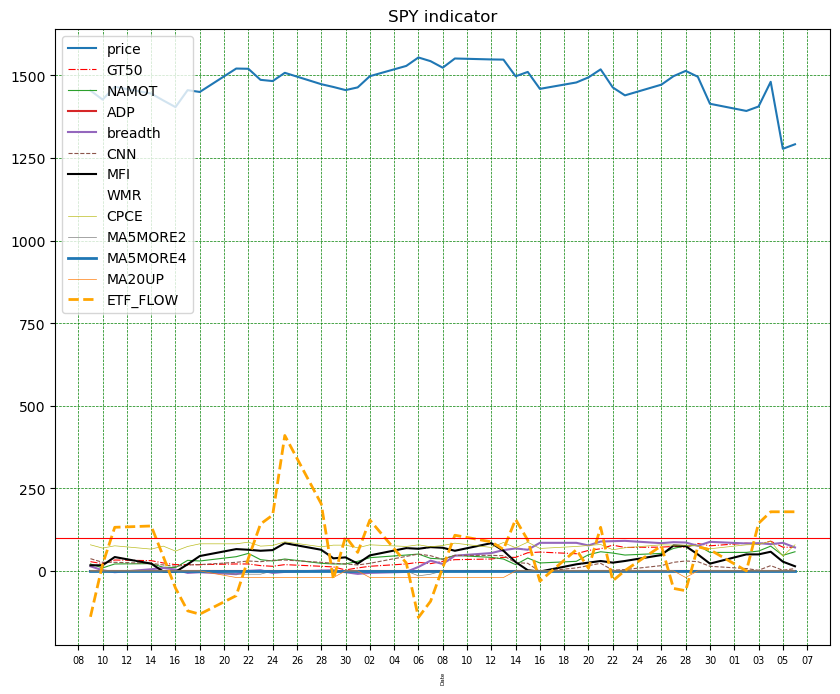

*** -8
MFI : 3/5 - 1/3
*** -1
GT50 : 2/5 - 0/1
*** -6
breadth : 3/11 - 3/7


[*********************100%***********************]  1 of 1 completed


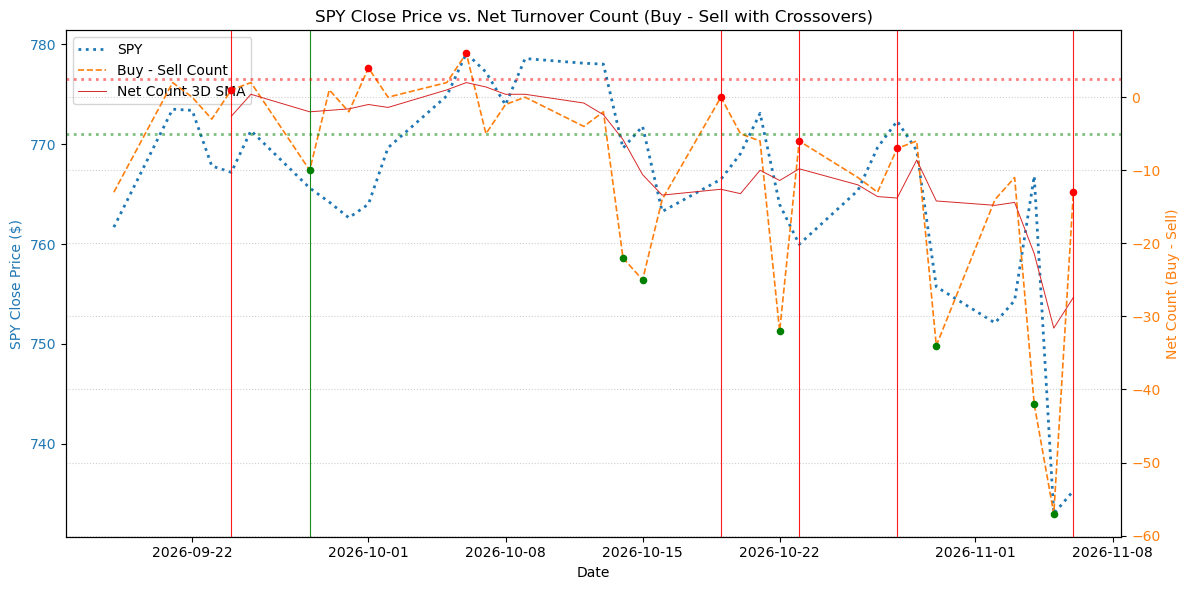

In [11]:
import mysql.connector
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.dates import DateFormatter
import matplotlib.dates as mdates
import matplotlib.ticker as ticker
import numpy as np
from datetime import datetime
import yfinance as yf

import configparser
config = configparser.ConfigParser()
config.read('config.ini')

def insert(df, row):
    insert_loc = df.index.max()

    if pd.isna(insert_loc):
        df.loc[0] = row
    else:
        df.loc[insert_loc + 1] = row
        
def get_ticker_date():
    # Create a datetime object representing the current date and time
    now = datetime.now()

    # Format the datetime object as a string using the strftime() method
    date_string = now.strftime("%y%m%d")

    # Print the formatted date string
    # print(date_string)
    return date_string
        
def getConnection():
    cnx = mysql.connector.connect(
#         host="lookupwd-24c.cz0e64ise636.us-east-1.rds.amazonaws.com",
#         host="novel9.czwuawkuwlbb.us-east-1.rds.amazonaws.com",
        
#         host="lookuwd-26.cw1w0ka6m85p.us-east-1.rds.amazonaws.com",
#         host="lookupwd-new26.ck3wisku88zi.us-east-1.rds.amazonaws.com",
        host=config['MySQL']['host'],
        user="novel",
        password="Test1234567",
        database="novel10"
    )
    return cnx
        

def getPrecent(df2, tickerDate, columnName):
    lastMFI = 0;
    countMFIP = 0;
    countMFIN = 0;
    countMFIPAll = 0;
    countMFINAll = 0;

    for index, row in df2.iterrows(): 
        currPriceDiff = row['priceDiff']
        currDate = row['dateAdded']
        currMFI = row[columnName]
        
        if lastMFI > 0:
            countMFIPAll = countMFIPAll + 1          
        if lastMFI > 0 and currPriceDiff > 3:
            countMFIP = countMFIP + 1            
#             print("P : " + str(currDate) + " : " + str(lastMFI) + " - " + str(currPriceDiff) ) 

        if lastMFI < 0:
            countMFINAll = countMFINAll + 1    
        if lastMFI < 0 and currPriceDiff < -3:
            countMFIN = countMFIN + 1
#             print("N : " +str(currDate) + " : " + str(lastMFI) + " - " + str(currPriceDiff) ) 
        if row[columnName] != 0:      
            lastMFI = row[columnName]
        else:
            lastMFI = 0
    
    if (abs(currMFI) > 0):        
        print("*** " + str(currMFI)) 
        print(columnName +  " : " + str(countMFIP) + "/" +  str(countMFIPAll) + " - " +  str(countMFIN) + "/" + str(countMFINAll)) 

#     else:               
#         print("--- ")
        
    result = 0
    if (countMFIPAll + countMFINAll > 0):
        result = (countMFIP + countMFIN) / (countMFIPAll + countMFINAll)
    
#     print("result " + str(result))
#     print("curr " + str(currMFI))
    if (result > 0.6 and abs(currMFI) > 0):
        print("update " + columnName) 
        datetime_object = datetime.strptime(tickerDate, "%y%m%d")
        cnx = getConnection()
        sql = "UPDATE ticker_indicator set diffFlag = %s WHERE tickerName = %s and dateAdded = %s"
        cursorUpdate = cnx.cursor()
        flagValue = result * 100
        if currMFI < 0: 
            flagValue = 0 - flagValue 
        cursorUpdate.execute(sql, (flagValue, columnName, datetime_object))
        cursorUpdate.close()
        print("%.0f%%" % (flagValue))
        cnx.commit()
        cnx.close()
        
    return result


def update_ticker_avg(avgValue, tickerDate):
    # Create a datetime object representing the current date and time
    cnx = getConnection()
#     datetime_object = datetime.strptime(tickerDate, "%y%m%d")    
    print(str(tickerDate) + " : avg = " + str(avgValue))
    sql = "UPDATE ticker_spy set avg = %s WHERE ticker = %s and dateAdded = %s"
    cursorUpdate = cnx.cursor()  
    cursorUpdate.execute(sql, (avgValue, "SPY", tickerDate))
    cursorUpdate.close()
    cnx.commit()
    cnx.close()

def get_prev_ticker_date():
    # Create a datetime object representing the current date and time
    cnx = getConnection()
    # Create a cursor object to execute SQL queries
    cursor = cnx.cursor()

    # Execute a SQL query to retrieve data
    query = "select max(dateAdded) from ticker_spy"

    cursor.execute(query)
    result = cursor.fetchall()
    maxId = 10000
    for i in result:
        now = i[0]
    cursor.close()
    cnx.close()

    # Format the datetime object as a string using the strftime() method
    date_string = now.strftime("%y%m%d")

    # Print the formatted date string
    # print(date_string)
    return date_string
    
        
def generateChart(dfin, isDiff):
     
    if isDiff:             
        fig, ax = plt.subplots(figsize=(10, 7))
#         plt.axhline(0, color="blue", alpha=1, linewidth=4)
    else:
        fig, ax = plt.subplots(figsize=(10, 8))

#     (t1 + t2 + t4 + t5 + t6 + t7 + t8
    dfin.dateAdded = dfin.dateAdded.dt.date
    dfin['price']=dfin['price'].astype(float)
    dfin['GT50']=dfin['GT50'].astype(float)
    dfin['NAMOT']=dfin['NAMOT'].astype(float)
    dfin['ADP']=dfin['ADP'].astype(float)
    dfin['breadth']=dfin['breadth'].astype(float)
    dfin['CNN']=dfin['CNN'].astype(float)
    dfin['MFI']=dfin['MFI'].astype(float)
    dfin['WMR']=dfin['WMR'].astype(float)
    dfin['CPCE']=dfin['CPCE'].astype(float)
    dfin['MA5MORE2']=dfin['MA5MORE2'].astype(float)
    dfin['MA5MORE4']=dfin['MA5MORE4'].astype(float)
    dfin['MA20UP']=dfin['MA20UP'].astype(float)
    dfin['ETF_FLOW']=dfin['ETF_FLOW'].astype(float)
    
    # Add x-axis and y-axis    
  
    if isDiff:         
        ax.plot(dfin.dateAdded,dfin['price'], ls='None', marker = 'o', ms = 5)
        line, = ax.plot(dfin.dateAdded,dfin['GT50'], ls='None', marker = "p", ms = 6)
        line.set_color("red")
        ax.plot(dfin.dateAdded,dfin['NAMOT'], ls='None', marker = "<", ms = 5)
        ax.plot(dfin.dateAdded,dfin['ADP'], ls='None', marker = ">", ms = 5)
        ax.plot(dfin.dateAdded,dfin['breadth'], ls='None', marker = "^", ms = 6)
        ax.plot(dfin.dateAdded,dfin['CNN'], ls='None', marker = "P", ms = 5)
        line, = ax.plot(dfin.dateAdded,dfin['MFI'], ls='None', marker = "s", ms = 5)   
        line.set_color("black")
        line, = ax.plot(dfin.dateAdded,dfin['WMR'], ls='None', marker = "*", ms = 5)
        line.set_color("azure")
        ax.plot(dfin.dateAdded,dfin['CPCE'], ls='None', marker = "8", ms = 5)
        line, =ax.plot(dfin.dateAdded,dfin['MA5MORE2'], ls='None', marker = "1", ms = 3)
        line.set_color("grey")    
        ax.plot(dfin.dateAdded,dfin['MA5MORE4'], ls='None', marker = "2", ms = 3)
        ax.plot(dfin.dateAdded,dfin['MA20UP'], ls='None', marker = ",", ms = 3)    
        line, = ax.plot(dfin.dateAdded,dfin['ETF_FLOW'], ls='None', marker = "d", ms = 5)    
        line.set_color("orange")    
    else:
        ax.plot(dfin.dateAdded,dfin['price'])
        line, = ax.plot(dfin.dateAdded,dfin['GT50'], ls='-.', linewidth=0.8) 
        line.set_color("red")
        ax.plot(dfin.dateAdded,dfin['NAMOT'], linewidth=0.8)
        ax.plot(dfin.dateAdded,dfin['ADP'])
        ax.plot(dfin.dateAdded,dfin['breadth'], linewidth=1.5)
        ax.plot(dfin.dateAdded,dfin['CNN'], ls='--', linewidth=0.8)
        line, = ax.plot(dfin.dateAdded,dfin['MFI'])    
        line.set_color("black")
        line, = ax.plot(dfin.dateAdded,dfin['WMR'], ls=':', linewidth=0.2)  
        line.set_color("azure")
        ax.plot(dfin.dateAdded,dfin['CPCE'], linewidth=0.5)
        line, =ax.plot(dfin.dateAdded,dfin['MA5MORE2'], ls='-', linewidth=0.5)
        line.set_color("grey")    
        ax.plot(dfin.dateAdded,dfin['MA5MORE4'],  linewidth=2)
        ax.plot(dfin.dateAdded,dfin['MA20UP'], ls='-', linewidth=0.5)
        line, = ax.plot(dfin.dateAdded,dfin['ETF_FLOW'], ls='--', linewidth=2) 
        line.set_color("orange")    

    # Set title and labels for axes
    ax.set(xlabel="Date",
           title="SPY indicator")
    
    plt.legend(['price', 'GT50', 'NAMOT',  'ADP',  'breadth',  'CNN',  'MFI',  'WMR', 'CPCE',
               'MA5MORE2', 'MA5MORE4', 'MA20UP', 'ETF_FLOW'], loc='upper left')
    
#     ax.xaxis.set_major_locator(mdates.WeekdayLocator(interval=1))
    
#     ax.MinorGridLineStyle = '-.'
       
    date_form = DateFormatter("%d")
    ax.xaxis.label.set_size(4)
    ax.xaxis.set_tick_params(labelsize='x-small')
    ax.xaxis.label.set_rotation('vertical')
    ax.xaxis.set_major_formatter(date_form)
    tick_spacing = 2
    ax.xaxis.set_major_locator(ticker.MultipleLocator(tick_spacing))
   
#     plt.grid(axis="x")
    
    plt.grid(color = 'green', linestyle = '--', linewidth = 0.5)
    
    
    if isDiff==False:      
        plt.axhline(y=100, color='r', linestyle='-', linewidth = 0.8)    
        
        plt.savefig('indicator-mrp.png')

    plt.show()
        
def get_spy_chart():
    startTime = "2023-02-18";
    cnx = getConnection()
 # Create a cursor object to execute SQL queries
    cursor = cnx.cursor()

    # Execute a SQL query to retrieve data
    query = "select ti.dateAdded, ti.tickerOrder, ti.tickerName, ti.trend, (tiv.price - 520) * 6, ti.diff from ticker_indicator ti " \
        "LEFT JOIN ticker_spy tiv  ON ti.dateAdded=tiv.dateAdded " \
        "where tiv.ticker = 'SPY' "\
            " and DATE(tiv.dateAdded) > DATE_SUB(CURDATE(), INTERVAL 60 DAY)" \
        " order by ti.dateAdded, ti.tickerOrder asc ";
    
    
#              " and tiv.dateAdded > '" + startTime + "'" \    
    
    cursor.execute(query)

    # Fetch the results of the query
    result = cursor.fetchall()
    
    df = pd.DataFrame(columns=['dateAdded', 'price', 'GT50',  'NAMOT',  'ADP',  'breadth',  'CNN',  'MFI',  'WMR', 'CPCE',
                              'MA5MORE2', 'MA5MORE4', 'MA20UP', 'ETF_FLOW'])
   
    
    df2 = pd.DataFrame(columns=['dateAdded', 'price', 'GT50',  'NAMOT',  'ADP',  'breadth',  'CNN',  'MFI',  'WMR', 'CPCE',
                              'MA5MORE2', 'MA5MORE4', 'MA20UP', 'ETF_FLOW', 'priceDiff'])

    lastDate = 0
    lastPrice = 0
    t1 = 0
    t2 = 0
    t3 = 0
    t4 = 0
    t5 = 0
    t6 = 0
    t7 = 0
    t8 = 0
    t9 = 0
    t10 = 0
    t11 = 0
    t12 = 0
    
    d1 = 0
    d2 = 0
    d3 = 0
    d4 = 0
    d5 = 0
    d6 = 0
    d7 = 0
    d8 = 0
    d9 = 0
    d10 = 0
    d11 = 0    
    d12 = 0    
    
    startY = 2
    pV = 3
    nV = -3
    
    showAdp = False
#     showAdp = True
    currentPrice = 0
    priceDiff = 0
        
    # Print the results
    for row in result:
        dateAdded = row[0]
        tickerOrder = int(row[1])        
        if row[3] is None:
            trend = 0
        else:
            trend = int(row[3])
        if row[5] is None:
            tickerDiff = 0
        else:
            tickerDiff = int(row[5])
        price = row[4]        
#         if tickerOrder == 3:
#             print(str(lastDate)  + " - " + str(dateAdded)  + " - " + str(tickerOrder) + " - " + str(trend) )

        if lastDate == dateAdded:
            if tickerOrder == 1:
                t1 = trend
                d1 = tickerDiff
                currentPrice = price
            elif tickerOrder == 2:
                t2 = trend
                d2 = tickerDiff
            elif tickerOrder == 3:
                t3 = trend if  showAdp else 0
                d3 = tickerDiff if  showAdp else 0                
            elif tickerOrder == 4:
                t4 = trend
                d4 = tickerDiff
            elif tickerOrder == 5:
                t5 = trend
                d5 = tickerDiff
            elif tickerOrder == 6:
                t6 = trend
                d6 = tickerDiff
            elif tickerOrder == 7:
                t7 = trend
                d7 = tickerDiff
            elif tickerOrder == 8:
                t8 = trend      
                d8 = tickerDiff      
            elif tickerOrder == 9:
                t9 = trend    
                d9 = tickerDiff 
            elif tickerOrder == 10:
                t10 = trend   
                d10 = tickerDiff                 
            elif tickerOrder == 11:
                t11 = trend
                d11 = tickerDiff           
            elif tickerOrder == 12:
                t12 = trend
                d12 = tickerDiff
        else:        
            if tickerOrder == 1:
                t1 = trend
                d1 = tickerDiff
                currentPrice = price
            elif tickerOrder == 9:
                t9 = trend
                d9 = tickerDiff
#                 currentPrice = price
            if lastPrice != 0:
                insert(df,[lastDate,lastPrice,lastT1,t2,t3,t4,t5,t6,t7,t8,t9,t10,t11, t12])    
#                 print(str(lastDate) + " : " + str(priceDiff) + " = " + str(currentPrice) + " - " + str(lastPrice) 
#                       + " - " +  str(d8)) 

                oldPriceDiff = priceDiff
                if priceDiff < 0:    
                    priceDiff = -16
                    lastD1 = 1 + startY if  lastD1 > pV else 0         
                    d2 = 2 + startY if  d2 > pV else 0       
                    d3 = 3 + startY if  d3 > pV else 0       
                    d4 = 4 + startY if  d4 > pV else 0       
                    d5 = 5 + startY if  d5 > pV else 0       
                    d6 = 6 + startY if  d6 > pV else 0       
                    d7 = 7 + startY if  d7 > pV else 0       
                    d8 = 8 + startY if  d8 > pV else 0     
                    d9 = 9 + startY if  d9 > pV else 0     
                    d10 = 10 + startY if  d10 > pV else 0     
                    d11 = 11 + startY if  d11 > pV else 0       
                    d12 = 12 + startY if  d12 > pV else 0                 
                if priceDiff > 0:         
                    priceDiff = 16             
                    lastD1 = -1 - startY if  lastD1 < nV else 0         
                    d2 = -2 - startY if  d2 < nV else 0       
                    d3 = -3 - startY if  d3 < nV else 0       
                    d4 = -4 - startY if  d4 < nV else 0       
                    d5 = -5 - startY if  d5 < nV else 0       
                    d6 = -6 - startY if  d6 < nV else 0       
                    d7 = -7 - startY if  d7 < nV else 0       
                    d8 = -8 - startY if  d8 < nV else 0     
                    d9 = -9 - startY if  d9 < nV else 0     
                    d10 = -10 - startY if  d10 < nV else 0     
                    d11 = -11 - startY if  d11 < nV else 0   
                    d12 = -12 - startY if  d12 < nV else 0 
                if priceDiff != 0:
                    insert(df2,[lastDate,priceDiff,lastD1,d2,d3,d4,d5,d6,d7,d8,d9,d10,d11,d12, oldPriceDiff])                              
                priceDiff = currentPrice - lastPrice  
        lastDate = dateAdded
        lastPrice = price
        lastD1= d1
        lastT1 = t1
    
    if tickerOrder == 1:
        t1 = trend
        d1 = tickerDiff
    elif tickerOrder == 2:
        t2 = trend
        d2 = tickerDiff
    elif tickerOrder == 3:
        t3 = trend if  showAdp else 0
        d3 = tickerDiff if  showAdp else 0
    elif tickerOrder == 4:
        t4 = trend
        d4 = tickerDiff
    elif tickerOrder == 5:
        t5 = trend
        d5 = tickerDiff
    elif tickerOrder == 6:
        t6 = trend
        d6 = tickerDiff
    elif tickerOrder == 7:
        t7 = trend
        d7 = tickerDiff
    elif tickerOrder == 8:
        t8 = trend      
        d8 = tickerDiff      
    elif tickerOrder == 9:
        t9 = trend     
        d9 = tickerDiff
    elif tickerOrder == 10:
        t10 = trend        
        d10 = tickerDiff            
    elif tickerOrder == 11:
        t11 = trend    
        d11 = tickerDiff      
    elif tickerOrder == 12:
        t12 = trend    
        d12 = tickerDiff
    
    insert(df,[lastDate,lastPrice,lastT1,t2,t3,t4,t5,t6,t7,t8,t9,t10,t11,t12])   
    
    avgValue = (t1 + t2 + t4 + t5 + t6 + t7 )/6
#     update_ticker_avg(avgValue, lastDate)

    print(str(avgValue));
        
#     print(str(lastDate) + " : " + str(priceDiff) + " = " + str(d1) + " , " + str(d2) 
#                       + " , " +  str(d3)+ " , " +  str(d4)+ " , " +  str(d5)+ " , " +  str(d6) 
#                       + " , " +  str(d7)     + " , " +  str(d8) + " , " +  str(d12))
    oldPriceDiff = priceDiff
    if priceDiff < 0:    
        priceDiff = -16
        d1 = 1 + startY if  d1 > pV else 0         
        d2 = 2 + startY if  d2 > pV else 0      
        d3 = 3 + startY if  d3 > pV else 0      
        d4 = 4 + startY if  d4 > pV else 0    
        d5 = 5 + startY if  d5 > pV else 0       
        d6 = 6 + startY if  d6 > pV else 0       
        d7 = 7 + startY if  d7 > pV else 0       
        d8 = 8 + startY if  d8 > pV else 0     
        d9 = 9 + startY if  d9 > pV else 0     
        d10 = 10 + startY if  d10 > pV else 0     
        d11 = 11 + startY if  d11 > pV else 0         
        d12 = 12 + startY if  d12 > pV else 0             
    if priceDiff > 0:         
        priceDiff = 16             
        d1 = -1 - startY if  d1 < nV else 0         
        d2 = -2 - startY if  d2 < nV else 0       
        d3 = -3 - startY if  d3 < nV else 0       
        d4 = -4 - startY if  d4 < nV else 0       
        d5 = -5 - startY if  d5 < nV else 0       
        d6 = -6 - startY if  d6 < nV else 0       
        d7 = -7 - startY if  d7 < nV else 0       
        d8 = -8 - startY if  d8 < nV else 0     
        d9 = -9 - startY if  d9 < nV else 0     
        d10 = -10 - startY if  d10 < nV else 0     
        d11 = -11 - startY if  d11 < nV else 0   
        d11 = -12 - startY if  d12 < nV else 0 
    insert(df2,[lastDate,priceDiff,lastD1,d2,d3,d4,d5,d6,d7,d8,d9,d10,d11,d12, oldPriceDiff])   
        

    cnx.close()
#     print(df)    

    generateChart(df, False)
    
    df_last_3 = df.tail(5)
  
    # Printing df_last_3
#     print(df_last_3) 

    
#     generateChart(df2, True)
    
    # tickerDate = '230324'
#     tickerDate = get_ticker_date()
    tickerDate = get_prev_ticker_date()
    
    getPrecent(df2, tickerDate, 'MFI')
    getPrecent(df2, tickerDate, 'GT50')
    getPrecent(df2, tickerDate, 'CNN')
    getPrecent(df2, tickerDate, 'breadth')
    getPrecent(df2, tickerDate, 'NAMOT')
    getPrecent(df2, tickerDate, 'CPCE')
    getPrecent(df2, tickerDate, 'WMR')
    getPrecent(df2, tickerDate, 'ETF_FLOW')

def plot_turnover_vs_spy():
    """
    db_config: dict containing MySQL connection info e.g., {'host': '...', 'user': '...', 'password': '...', 'database': '...'}
    """
    # 1. Fetch data from MySQL database
    cnx = getConnection()
    cursor = cnx.cursor()
    
    query = "SELECT update_date, sell_cnt, buy_cnt FROM turnover_tickers_cnt"
    cursor.execute(query)
    result = cursor.fetchall()
    
    cursor.close()
    cnx.close()
    if not result:
        print("No data retrieved from database.")
        return
    
    # Ensure update_date is in datetime format and sort
    df_db = pd.DataFrame(result, columns=['update_date', 'sell_cnt', 'buy_cnt'])
    df_db['update_date'] = pd.to_datetime(df_db['update_date'])
    df_db = df_db.sort_values('update_date')
    
    # Calculate net count with a small positional nudge so the two lines don't overlap
    net_cnt = df_db['sell_cnt'] - df_db['buy_cnt']
    net_cnt = net_cnt.where(df_db['sell_cnt'] <= df_db['buy_cnt'], net_cnt + df_db['sell_cnt'] // 4)
    net_cnt = net_cnt.where(df_db['sell_cnt'] >= df_db['buy_cnt'], net_cnt - df_db['buy_cnt'] // 4)
    df_db['net_cnt'] = net_cnt
    
    # Calculate 3-day SMA for net count
    df_db['net_cnt_sma5'] = df_db['net_cnt'].rolling(window=5).mean()
    
    # 2. Get SPY data from yfinance starting from the minimum date in DB
    min_date = df_db['update_date'].min().strftime('%Y-%m-%d')
    spy_df = yf.download('SPY', start=min_date)
    spy_df = spy_df.reset_index()
    
    if isinstance(spy_df.columns, pd.MultiIndex):
        spy_df.columns = [f'{a}_{b}' if b else a for a, b in spy_df.columns]
        
    spy_df['Date'] = pd.to_datetime(spy_df['Date']).dt.tz_localize(None)
    
    # 3. Merge SPY Close price with database data
    close_col = 'Close_SPY' if 'Close_SPY' in spy_df.columns else 'Close'
    spy_df['SPY_Close'] = spy_df[close_col]
    
    merged_df = pd.merge(df_db, spy_df[['Date', 'SPY_Close']], left_on='update_date', right_on='Date', how='inner')
    
    # 4. Draw two-line chart using dual y-axes
    fig, ax1 = plt.subplots(figsize=(12, 6))
    
    # Plot SPY Close price on the left y-axis
    color_spy = 'tab:blue'
    ax1.set_xlabel('Date')
    ax1.set_ylabel('SPY Close Price ($)', color=color_spy)
    line1 = ax1.plot(merged_df['update_date'], merged_df['SPY_Close'], color=color_spy, label='SPY', linestyle='dotted' , linewidth=2, alpha=1)
    ax1.tick_params(axis='y', labelcolor=color_spy)
    
    # Create second y-axis sharing the same x-axis for net count
    ax2 = ax1.twinx()
    color_net = 'tab:orange'
    ax2.set_ylabel('Net Count (Buy - Sell)', color=color_net)
    line2 = ax2.plot(merged_df['update_date'], merged_df['net_cnt'], color=color_net, label='Buy - Sell Count', linestyle='--', linewidth=1.2)
    
    # Plot 3-day SMA line on ax2
    color_sma = 'tab:red'
    line3 = ax2.plot(merged_df['update_date'], merged_df['net_cnt_sma5'], color=color_sma, label='Net Count 3D SMA', linewidth=0.7)
    ax2.tick_params(axis='y', labelcolor=color_net)
    # Vertical markers based on the difference between sma5 and current
    # net_cnt, gated by the prior day's net_cnt direction:
    # green when sma5 - net_cnt > limit and the prior value is not lower
    # (net_cnt falling/flat); red when sma5 - net_cnt < -limit and the
    # prior value is not greater (net_cnt rising/flat).
    net_cnt = merged_df['net_cnt']
    diff = merged_df['net_cnt_sma5'] - net_cnt
    prev_cnt = net_cnt.shift(1)
    diff_limit = 3.5
    prev_was_buy = False
    prev_was_sell = False
    lowest_down = None  # lowest net_cnt seen on a down day (net_cnt < prev day)
    highest_up = None   # highest net_cnt seen on an up day (net_cnt > prev day)
    for d, diff_val, v, prev_v in zip(merged_df['update_date'], diff, net_cnt, prev_cnt):
        if pd.isna(d) or pd.isna(diff_val) or pd.isna(prev_v):
            continue
        drew_green = False
        drew_red = False
        # A down turn is a day where net_cnt fell below the previous day.
        is_down = v < prev_v
        # An up turn is a day where net_cnt rose above the previous day.
        is_up = v > prev_v
        # If net_cnt makes a new low below the last down low, do not buy.
        new_low = lowest_down is not None and v < lowest_down
        # If net_cnt makes a new high above the last up high, do not sell.
        new_high = highest_up is not None and v > highest_up
        if diff_val > diff_limit * 2 and not (prev_v < v):
                ax2.scatter(d, v, color='green', s=20, zorder=5)
                if not prev_was_sell and not new_low:
                    ax2.axvline(x=d, color='green', linestyle='-', linewidth=0.8, alpha=0.9)
                    drew_green = True
        elif diff_val < 0 - diff_limit and not (prev_v > v):
            ax2.scatter(d, v, color='red', s=20, zorder=5)
            if not prev_was_buy and not new_high:
                ax2.axvline(x=d, color='red', linestyle='-', linewidth=0.8, alpha=0.9)
                drew_red = True
        # Remember the lowest down point only on down days.
        if is_down:
            lowest_down = v if lowest_down is None else min(lowest_down, v)
        # Remember the highest up point only on up days.
        if is_up:
            highest_up = v if highest_up is None else max(highest_up, v)
        prev_was_buy = drew_green
        prev_was_sell = drew_red
        
    # Horizontal reference lines on the net count axis
    ax2.axhline(y=-5, color='green', linestyle=':', linewidth=2, alpha=0.5)
    ax2.axhline(y=2.5, color='red', linestyle=':', linewidth=2, alpha=0.5)
    
    # Combine legends from both axes
    lines = line1 + line2 + line3
    labels = [l.get_label() for l in lines]
    ax1.legend(lines, labels, loc='upper left')
    
    plt.title('SPY Close Price vs. Net Turnover Count (Buy - Sell with Crossovers)')
    plt.grid(True, linestyle=':', alpha=0.6)
    plt.tight_layout()
    plt.show()
    
# pd.set_option('display.max_rows', 2000)
get_spy_chart()
plot_turnover_vs_spy()

0 - 0 : None - None - SPY 2026-11-06 00:00:00
0 - 0 : None - None - SPY 2026-11-05 00:00:00
0 - 0 : None - None - SPY 2026-11-04 00:00:00
avgNum - 415.893023255814
avgNumBefore - 19.73255813953488
avgNumDown - 407.89302325581394
last_sma_value - 41.056666666666665
261106 : avg = 41.056666666666665


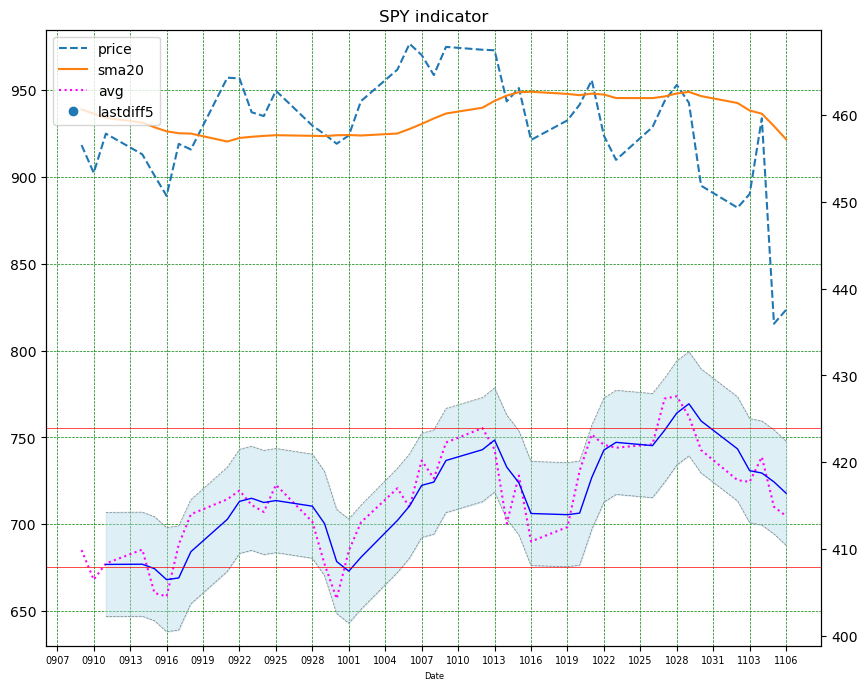

0 - 0 : None - None - QQQ 2026-11-06 00:00:00
0 - 0 : None - None - QQQ 2026-11-05 00:00:00
0 - 0 : None - None - QQQ 2026-11-04 00:00:00


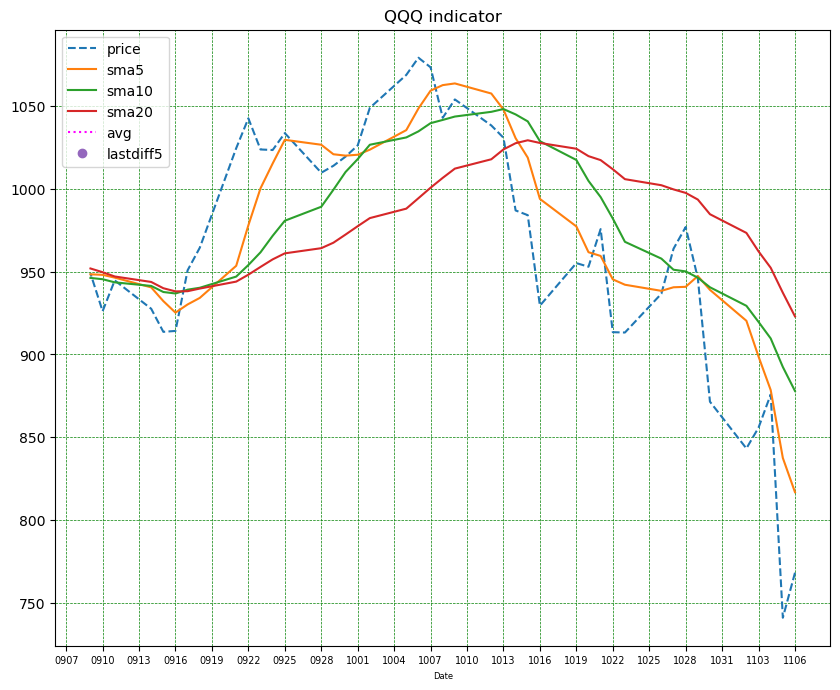

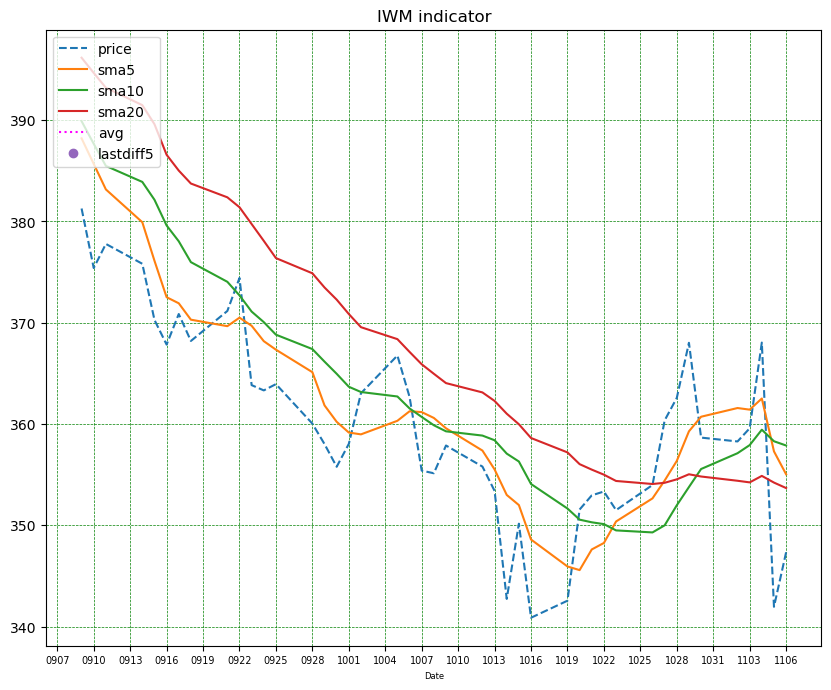

SPY - 0
QQQ - 0
IWM - 0


In [5]:
import mysql.connector
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.dates import DateFormatter
import matplotlib.dates as mdates
import configparser
config = configparser.ConfigParser()
config.read('config.ini')


AVG_OFFSET = 20    
AVG_UP_LIMIT = 40

def insert(df, row):
    insert_loc = df.index.max()

    if pd.isna(insert_loc):
        df.loc[0] = row
    else:
        df.loc[insert_loc + 1] = row

def fp(x):
    if x is None:
        return 100;
    return x

def getConnection():
    cnx = mysql.connector.connect(
#         host="lookupwd-24c.cz0e64ise636.us-east-1.rds.amazonaws.com",
#         host="novel9.czwuawkuwlbb.us-east-1.rds.amazonaws.com",
        
#         host="lookuwd-26.cw1w0ka6m85p.us-east-1.rds.amazonaws.com",
#         host="lookupwd-new26.ck3wisku88zi.us-east-1.rds.amazonaws.com",
        host=config['MySQL']['host'],
        user="novel",
        password="Test1234567",
        database="novel10"
    )
    return cnx
        

def get_prev_ticker_date():
    # Create a datetime object representing the current date and time
    cnx = getConnection()
    # Create a cursor object to execute SQL queries
    cursor = cnx.cursor()

    # Execute a SQL query to retrieve data
    query = "select max(dateAdded) from ticker_spy"

    cursor.execute(query)
    result = cursor.fetchall()
    maxId = 10000
    for i in result:
        now = i[0]
    cursor.close()
    cnx.close()

    # Format the datetime object as a string using the strftime() method
    date_string = now.strftime("%y%m%d")

    # Print the formatted date string
    # print(date_string)
    return date_string

def update_ticker_avg2(avgValue, ctype, colname):
    # Create a datetime object representing the current date and time
    cnx = getConnection()
#     datetime_object = datetime.strptime(tickerDate, "%y%m%d")    

    # Create a cursor object to execute SQL queries
    cursor = cnx.cursor()

    # Execute a SQL query to retrieve data
    query = "select max(dateAdded) from ticker_spy"

    cursor.execute(query)
    result = cursor.fetchall()
    for i in result:
        now = i[0]
    cursor.close()

    # Format the datetime object as a string using the strftime() method
    date_string = now.strftime("%y%m%d")

    # Print the formatted date string
    # print(date_string)
    print(date_string + " : avg = " + str(avgValue))
    sql = "UPDATE ticker_spy set " + colname + " = %s WHERE ticker = %s and dateAdded = %s"
    cursorUpdate = cnx.cursor()  
    cursorUpdate.execute(sql, (avgValue, ctype, date_string))
    cursorUpdate.close()
    cnx.commit()
    cnx.close()
        
def calculate_sma_before(df, window_size=4, band_size=6):
    df = df.sort_values(by='dateAdded', ascending=True)
    df['sma_sma3_before'] = df['avg'].rolling(window=window_size).mean()

    return df

def calculate_sma(df, window_size=4, band_size=6):
    df = df.sort_values(by='dateAdded', ascending=True)
    df['sma_sma3'] = df['avg'].rolling(window=window_size).mean()
    df['sma_h3'] = df['sma_sma3'] + band_size
    df['sma_l3'] = df['sma_sma3'] - band_size

    return df

def get_spy_chart(tickerName):
    startTime = "2023-02-18";
    cnx = mysql.connector.connect(
#         host="lookupwd-24c.cz0e64ise636.us-east-1.rds.amazonaws.com",
#         host="novel9.czwuawkuwlbb.us-east-1.rds.amazonaws.com",
        
#         host="lookuwd-26.cw1w0ka6m85p.us-east-1.rds.amazonaws.com",
#         host="lookupwd-new26.ck3wisku88zi.us-east-1.rds.amazonaws.com",
        
        host=config['MySQL']['host'],
        user="novel",
        password="Test1234567",
        database="novel10"
    )
 # Create a cursor object to execute SQL queries
    cursor = cnx.cursor()
    
    currDate = get_prev_ticker_date()
    

    # Execute a SQL query to retrieve data
    query = "select  tiv.dateAdded, tiv.price, tiv.sma5,  tiv.sma20, tiv.avg, tiv.lastdiff5, tiv.sma10, tiv.call_count,  "\
            " tiv.put_count from  ticker_spy tiv  "\
            " where tiv.ticker = %(index_name)s "\
            " and DATE(tiv.dateAdded) > DATE_SUB(CURDATE(), INTERVAL 60 DAY)" \
        " order by tiv.dateAdded desc "   
    
#     " and tiv.dateAdded > '" + startTime + "'"

    cursor.execute(query, {'index_name': tickerName})

    # Fetch the results of the query
    result = cursor.fetchall()    
    
    df = pd.DataFrame(columns=['dateAdded', 'price', 'sma5',  'sma10', 'sma20', 'avg', 'lastdiff5', 'call', 'put' ])
    
    offset = 400
    lastdiff5Value = 0
    lastdiff5 = None 
    call = None    
    put = None
    total_rows = len(result)
    callput_pct=0.3
    
    # Print the results
    for index, row in enumerate(result):
        dateAdded = row[0]
        price = row[1]  
        avg = None
        if (tickerName == "SPY"):
            avg = row[4]    
            callput_pct = 0.6
        if  (tickerName == "SPY" or tickerName == "QQQ")  :
            call1 = 0 if row[7] is None else row[7]
            put1 = 0 if row[8] is None else row[8]
            call2 = 0 if call1 == 0 else call1 / (call1+put1) * (offset) * callput_pct + 300
            put2 = 0 if put1 == 0 else put1 / (call1+put1) *  (offset) * callput_pct + 300           
#             call = int(call2) * 2 if call2 < 300 else int(call2)
#             put = int(put2) * 2 if put2 < 300 else int(put2)
            call = None if call2 == 0 else int(call2)
            put = None if put2 == 0 else int(put2)
            if index < 3:
                print(f"{call1} - {put1} : {call} - {put} - {tickerName} {dateAdded}")
        lastdiff5 = row[5]        
        if dateAdded.strftime("%y%m%d") == currDate:            
            lastdiff5Value = lastdiff5
        if (abs(fp(lastdiff5)) > 0.3):
            lastdiff5 = None
        else:            
            lastdiff5 = 1 - abs(lastdiff5)
        if row[2] == 0:
            sma5 = offset
        else:             
            sma5 = row[2]
        
        if row[3] == 0:
            sma20 = offset
        else:             
            sma20 = row[3]      
            
        if row[6] == 0:
            sma10 = offset
        else:             
            sma10 = row[6]      
            
        insert(df,[dateAdded,price,sma5,sma10, sma20, avg, lastdiff5, call, put])
        
    
    cnx.close()
    
    
    fig, ax = plt.subplots(figsize=(10, 8))
    
    baseValue = offset    
    if (tickerName == "QQQ"):
         baseValue = 340        
    if (tickerName == "IWM"):
         baseValue = 160
    
    avgNumBefore =  np.mean(df['avg'].astype(float))
    windowSize=3
    rangeRate = 2.5
    priceOffset = -100
    pricePct = 2
    if (tickerName == "SPY"):  
        priceOffset = -500
        pricePct = 3.5    
    if (tickerName == "QQQ"):
        priceOffset = -400
        pricePct = 3
    df.dateAdded = df.dateAdded.dt.date
    df['price']=df['price'].astype(float)
    df['price']=(df['price'].astype(float) + priceOffset) * pricePct 
    df['sma5']=(df['sma5'].astype(float) + priceOffset) * pricePct 
    df['sma10']=(df['sma10'].astype(float) + priceOffset) * pricePct 
    df['sma20']=(df['sma20'].astype(float) + priceOffset) * pricePct 
    
    if (tickerName == "SPY"):  
        calculate_sma_before
        df = calculate_sma_before(df, windowSize)
    
    df['avg']=df['avg'].astype(float) / rangeRate + offset
    df['lastdiff5']=df['lastdiff5'].astype(float)  * 10 + baseValue
#     print( df['sma_sma3_before']       )
    
    if (tickerName == "SPY"):    
        df = calculate_sma(df, windowSize)        
        
    avgNum =  np.mean(df['avg'])   
    
    
    # For SPY, split the two trend groups onto dual y-axes (same layout as
    # plot_turnover_vs_spy): price/sma group on the left axis, indicators on the right.
    ax2 = ax.twinx() if (tickerName == "SPY") else ax
    ax.plot(df.dateAdded,df['price'], ls='--', label='price')
    if (tickerName != "SPY"):
        ax.plot(df.dateAdded,df['sma5'], label='sma5')
        ax.plot(df.dateAdded,df['sma10'], label='sma10')
    ax.plot(df.dateAdded,df['sma20'], label='sma20')
    ax2.plot(df.dateAdded,df['avg'], ls=':', color="magenta", linewidth=1.5, label='avg')
    ax2.plot(df.dateAdded,df['lastdiff5'], ls='None', marker = "o", ms = 6, label='lastdiff5')
    if (tickerName == "SPY"):    
        ax2.plot(df.dateAdded,df['sma_h3'], ls='dashed', color="grey",  linewidth=0.5)
        ax2.plot(df.dateAdded,df['sma_l3'], ls='dashed', color="grey",  linewidth=0.5)
        ax2.plot(df.dateAdded,df['sma_sma3'], color="blue", linewidth=1)   
        ax2.fill_between(df.dateAdded, df['sma_h3'], df['sma_l3'], 
                         where=(df['sma_l3'] < df['sma_h3']), interpolate=True, color='lightblue', alpha=0.4)
        
    if  (tickerName == "SPY" or tickerName == "QQQ")  :
        ax2.plot(df.dateAdded,df['call'], ls='--', color="green",  linewidth=1.5)   
#         ax.plot(df.dateAdded,df['put'], ls=':', color="red",  linewidth=1.2)     
    
    
    # Set title and labels for axes
    ax.set(xlabel="Date",
#            ylabel="price",
           title=tickerName + " indicator")
   
    
    handles1, labels1 = ax.get_legend_handles_labels()
    handles2, labels2 = ax2.get_legend_handles_labels() if ax2 is not ax else ([], [])
    ax.legend(handles1 + handles2, labels1 + labels2, loc='upper left')
#     ax.xaxis.set_major_locator(mdates.WeekdayLocator(interval=1))

    ax.xaxis.label.set_size(6)
    ax.xaxis.set_tick_params(labelsize='x-small')
    date_form = DateFormatter("%m%d")
    ax.xaxis.set_major_formatter(date_form)
    tick_spacing = 3
    ax.xaxis.set_major_locator(ticker.MultipleLocator(tick_spacing))
    
    
    avgRange =  np.mean(df['price'])  -100
    offsetRange=offset
    if (tickerName == "QQQ"):
        rangeRate = 3
        offsetRange=avgRange
    if (tickerName == "IWM"):
        rangeRate = 4
        offsetRange=155
        
    if (tickerName == "SPY"):
        last_sma_value = (df['sma_sma3_before'].iloc[-1].astype(float) ) 
        avgNumBefore = avgNumBefore - AVG_OFFSET
        # Keep the two axes in separate vertical bands so their lines don't overlap.
        p_lo, p_hi = ax.get_ylim()
        ax.set_ylim(p_lo - (p_hi - p_lo), p_hi)   # price/sma group in the upper band
        i_lo, i_hi = ax2.get_ylim()
        ax2.set_ylim(i_lo, i_hi + (i_hi - i_lo))  # indicator group in the lower band
        ax2.axhline(y=(avgNumBefore + AVG_UP_LIMIT) / rangeRate + offsetRange, color='r', linestyle='-', linewidth = 0.5)        
        ax2.axhline(y=(avgNumBefore) / rangeRate + offsetRange, color='r', linestyle='-', linewidth = 0.5)      
        print("avgNum - " + str(avgNum)       )
        print("avgNumBefore - " + str(avgNumBefore)   )
        print("avgNumDown - " + str((avgNumBefore ) / rangeRate + offsetRange)   )
        print("last_sma_value - " + str(last_sma_value)   )
#         print(df.tail(5))
#         avgNumBefore
        update_ticker_avg2(float(last_sma_value), 'SPY', 'avg2')
        
        
    
        plt.savefig('indicator-spy.png')
        
        
#     plt.grid(axis="x")
    
    ax.grid(color = 'green', linestyle = '--', linewidth = 0.5)
    

    plt.show()
    

    
    df_last_3 = df.head(5)

    if (abs(fp(lastdiff5Value)) <= 0.3):
        return lastdiff5Value
    return 0

        
def get_spy_chart3(tickerName):
    startTime = "2023-02-18";
    cnx = mysql.connector.connect(
#         host="lookupwd-24c.cz0e64ise636.us-east-1.rds.amazonaws.com",
#         host="novel9.czwuawkuwlbb.us-east-1.rds.amazonaws.com",
        
#         host="lookuwd-26.cw1w0ka6m85p.us-east-1.rds.amazonaws.com",
#         host="lookupwd-new26.ck3wisku88zi.us-east-1.rds.amazonaws.com",
        
        host=config['MySQL']['host'],
        user="novel",
        password="Test1234567",
        database="novel10"
    )
 # Create a cursor object to execute SQL queries
    cursor = cnx.cursor()
    
    currDate = get_prev_ticker_date()
    

    # Execute a SQL query to retrieve data
    query = "select  tiv.dateAdded, tiv.price, tiv.sma5,  tiv.sma20, tiv.avg, tiv.lastdiff5, tiv.sma10, tiv.call_count,  "\
            " tiv.put_count from  ticker_spy tiv  "\
            " where tiv.ticker = %(index_name)s "\
            " and DATE(tiv.dateAdded) > DATE_SUB(CURDATE(), INTERVAL 60 DAY)" \
        " order by tiv.dateAdded desc "   
    
#     " and tiv.dateAdded > '" + startTime + "'"

    cursor.execute(query, {'index_name': tickerName})

    # Fetch the results of the query
    result = cursor.fetchall()    
    
    df = pd.DataFrame(columns=['dateAdded', 'price', 'sma5',  'sma10', 'sma20', 'avg', 'lastdiff5', 'call', 'put' ])
    
    offset = 400
    lastdiff5Value = 0
    lastdiff5 = None 
    call = None    
    put = None
    total_rows = len(result)
    callput_pct=0.3
    
    # Print the results
    for index, row in enumerate(result):
        dateAdded = row[0]
        price = row[1]  
        avg = None
        if (tickerName == "SPY"):
            avg = row[4]    
            callput_pct = 0.6
        if  (tickerName == "SPY" or tickerName == "QQQ")  :
            call1 = 0 if row[7] is None else row[7]
            put1 = 0 if row[8] is None else row[8]
            call2 = 0 if call1 == 0 else call1 / (call1+put1) * (offset) * callput_pct + 300
            put2 = 0 if put1 == 0 else put1 / (call1+put1) *  (offset) * callput_pct + 300           
#             call = int(call2) * 2 if call2 < 300 else int(call2)
#             put = int(put2) * 2 if put2 < 300 else int(put2)
            call = None if call2 == 0 else int(call2)
            put = None if put2 == 0 else int(put2)
            if index < 3:
                print(f"{call1} - {put1} : {call} - {put} - {tickerName} {dateAdded}")
        lastdiff5 = row[5]        
        if dateAdded.strftime("%y%m%d") == currDate:            
            lastdiff5Value = lastdiff5
        if (abs(fp(lastdiff5)) > 0.3):
            lastdiff5 = None
        else:            
            lastdiff5 = 1 - abs(lastdiff5)
        if row[2] == 0:
            sma5 = offset
        else:             
            sma5 = row[2]
        
        if row[3] == 0:
            sma20 = offset
        else:             
            sma20 = row[3]      
            
        if row[6] == 0:
            sma10 = offset
        else:             
            sma10 = row[6]      
            
        insert(df,[dateAdded,price,sma5,sma10, sma20, avg, lastdiff5, call, put])
        
    
    cnx.close()
    
    
    fig, ax = plt.subplots(figsize=(10, 8))
    
    baseValue = offset    
    if (tickerName == "QQQ"):
         baseValue = 340        
    if (tickerName == "IWM"):
         baseValue = 160
    
    avgNumBefore =  np.mean(df['avg'].astype(float))
    windowSize=3
    rangeRate = 2.5
    priceOffset = -100
    pricePct = 2
    if (tickerName == "SPY"):  
        priceOffset = -500
        pricePct = 3.5    
    if (tickerName == "QQQ"):
        priceOffset = -400
        pricePct = 3
    df.dateAdded = df.dateAdded.dt.date
    df['price']=df['price'].astype(float)
    df['price']=(df['price'].astype(float) + priceOffset) * pricePct 
    df['sma5']=(df['sma5'].astype(float) + priceOffset) * pricePct 
    df['sma10']=(df['sma10'].astype(float) + priceOffset) * pricePct 
    df['sma20']=(df['sma20'].astype(float) + priceOffset) * pricePct 
    
    if (tickerName == "SPY"):  
        calculate_sma_before
        df = calculate_sma_before(df, windowSize)
    
    df['avg']=df['avg'].astype(float) / rangeRate + offset
    df['lastdiff5']=df['lastdiff5'].astype(float)  * 10 + baseValue
#     print( df['sma_sma3_before']       )
    
    if (tickerName == "SPY"):    
        df = calculate_sma(df, windowSize)        
        
    avgNum =  np.mean(df['avg'])   
    
    
    ax.plot(df.dateAdded,df['price'], ls='--')
    ax.plot(df.dateAdded,df['sma5'])
    ax.plot(df.dateAdded,df['sma10'])
    ax.plot(df.dateAdded,df['sma20'])
    ax.plot(df.dateAdded,df['avg'], ls=':', color="magenta", linewidth=1.5)
    ax.plot(df.dateAdded,df['lastdiff5'], ls='None', marker = "o", ms = 6)
    if (tickerName == "SPY"):    
        ax.plot(df.dateAdded,df['sma_h3'], ls='dashed', color="grey",  linewidth=0.5)
        ax.plot(df.dateAdded,df['sma_l3'], ls='dashed', color="grey",  linewidth=0.5)
        ax.plot(df.dateAdded,df['sma_sma3'], color="blue", linewidth=1)   
        plt.fill_between(df.dateAdded, df['sma_h3'], df['sma_l3'], 
                         where=(df['sma_l3'] < df['sma_h3']), interpolate=True, color='lightblue', alpha=0.4)
        
    if  (tickerName == "SPY" or tickerName == "QQQ")  :
        ax.plot(df.dateAdded,df['call'], ls='--', color="green",  linewidth=1.5)   
#         ax.plot(df.dateAdded,df['put'], ls=':', color="red",  linewidth=1.2)     
    
    
    # Set title and labels for axes
    ax.set(xlabel="Date",
#            ylabel="price",
           title=tickerName + " indicator")
   
    
    plt.legend(['price', 'sma5','sma10', 'sma20', 'avg', 'lastdiff5'], loc='upper left')
#     ax.xaxis.set_major_locator(mdates.WeekdayLocator(interval=1))

    ax.xaxis.label.set_size(6)
    ax.xaxis.set_tick_params(labelsize='x-small')
    date_form = DateFormatter("%m%d")
    ax.xaxis.set_major_formatter(date_form)
    tick_spacing = 3
    ax.xaxis.set_major_locator(ticker.MultipleLocator(tick_spacing))
    
    
    avgRange =  np.mean(df['price'])  -100
    offsetRange=offset
    if (tickerName == "QQQ"):
        rangeRate = 3
        offsetRange=avgRange
    if (tickerName == "IWM"):
        rangeRate = 4
        offsetRange=155
        
    if (tickerName == "SPY"):
        last_sma_value = (df['sma_sma3_before'].iloc[-1].astype(float) ) 
        avgNumBefore = avgNumBefore - AVG_OFFSET
        plt.axhline(y=(avgNumBefore + AVG_UP_LIMIT) / rangeRate + offsetRange, color='r', linestyle='-', linewidth = 0.5)        
        plt.axhline(y=(avgNumBefore) / rangeRate + offsetRange, color='r', linestyle='-', linewidth = 0.5)      
        print("avgNum - " + str(avgNum)       )
        print("avgNumBefore - " + str(avgNumBefore)   )
        print("avgNumDown - " + str((avgNumBefore ) / rangeRate + offsetRange)   )
        print("last_sma_value - " + str(last_sma_value)   )
#         print(df.tail(5))
#         avgNumBefore
        update_ticker_avg2(float(last_sma_value), 'SPY', 'avg2')
        
        
    
        plt.savefig('indicator-spy.png')
        
        
#     plt.grid(axis="x")
    
    plt.grid(color = 'green', linestyle = '--', linewidth = 0.5)
    

    plt.show()
    

    
    df_last_3 = df.head(5)

    if (abs(fp(lastdiff5Value)) <= 0.3):
        return lastdiff5Value
    return 0
  
    # Printing df_last_3
#     print(df_last_3)
    
lastdiff5Value1 = get_spy_chart('SPY')
lastdiff5Value2 = get_spy_chart('QQQ')
lastdiff5Value3 = get_spy_chart('IWM')


print("SPY - " + str(lastdiff5Value1))
print("QQQ - " + str(lastdiff5Value2))
print("IWM - " + str(lastdiff5Value3))


   dateAdded  priceDiff_x  priceDiff_y  vix_pct  countDip   price
37     11-02        -3.62     2.123457      0.0       4.0  752.10
38     11-03         2.25     1.400000      0.0       4.0  754.35
39     11-04        12.46     1.520988      0.0       4.0  766.81
40     11-05       -33.81     0.204545      3.0       4.0  733.00
41     11-06         2.29     1.000000      3.0       4.0  735.29
261106 QQQ : avg = -3.616823578947368
261106 IWM : avg = 0.763413043478261
[0.5617285000000001, 0.19999999999999996, 0.260494, -6.36364, 0.0]
last_sma_value - -1.0682835000000002
261106update_count_avg : avg = -1.0682835000000002


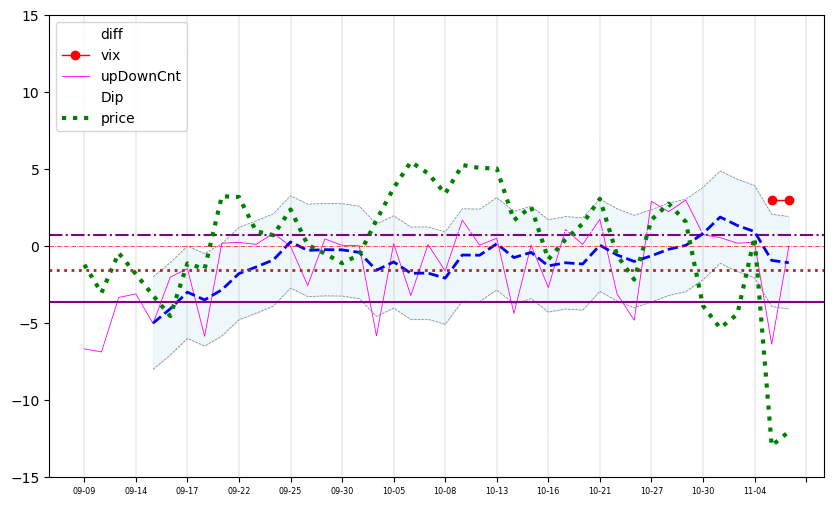

<Figure size 640x480 with 0 Axes>

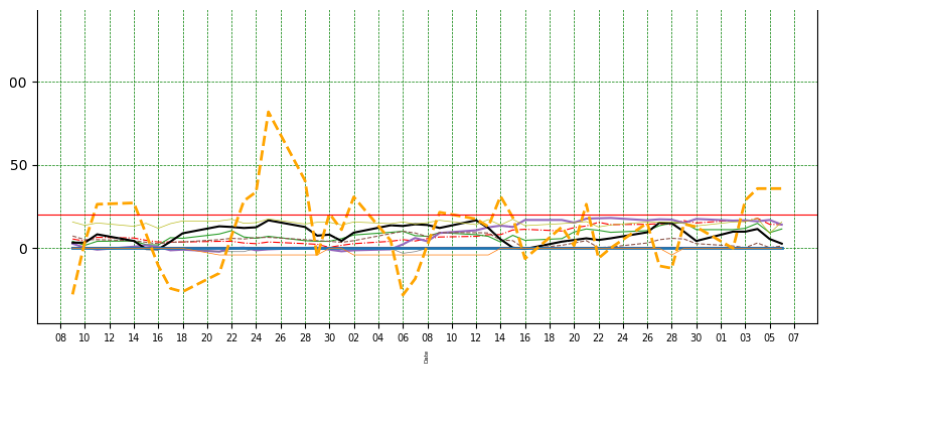

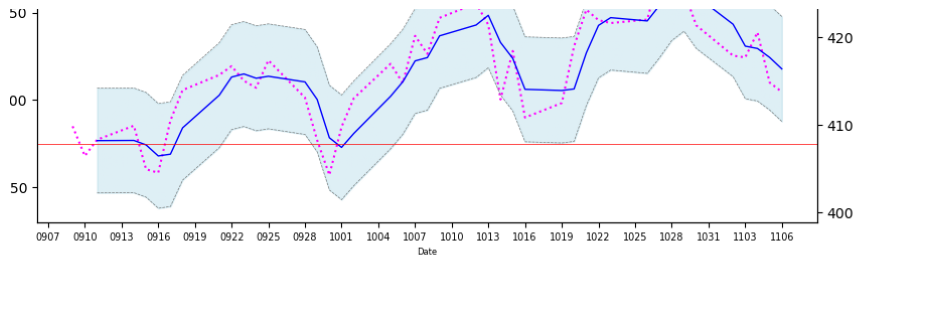


=== Sell Score Weights (past 0.8y, >P70, 10d forward) ===
Indicator    Sell后天下跌概率             Signals    Weight    
------------------------------------------------------
avg_ind      92%                  12         0.299
breadth      75%                  12         0.245
avg_cnt      60%                  15         0.196
mfi          80%                  20         0.261
Sum                                            1.000

sell_score = 0.299 * avg_ind + 0.245 * breadth + 0.196 * avg_cnt + 0.261 * mfi
=== Sell Score (dynamic weights from 1-year history) ===
 dateAdded  price  avg_ind_norm  breadth_norm  avg_cnt_norm  mfi_norm  sell_score
2026-11-02 752.10         52.96         92.23         82.94     40.88       65.28
2026-11-03 754.35         46.18         93.20         77.73     40.88       62.47
2026-11-04 766.81         45.47         90.29         74.03     46.72       62.34
2026-11-05 733.00         42.71         94.17         56.21     24.82       53.27
2026-11-06 735.29       

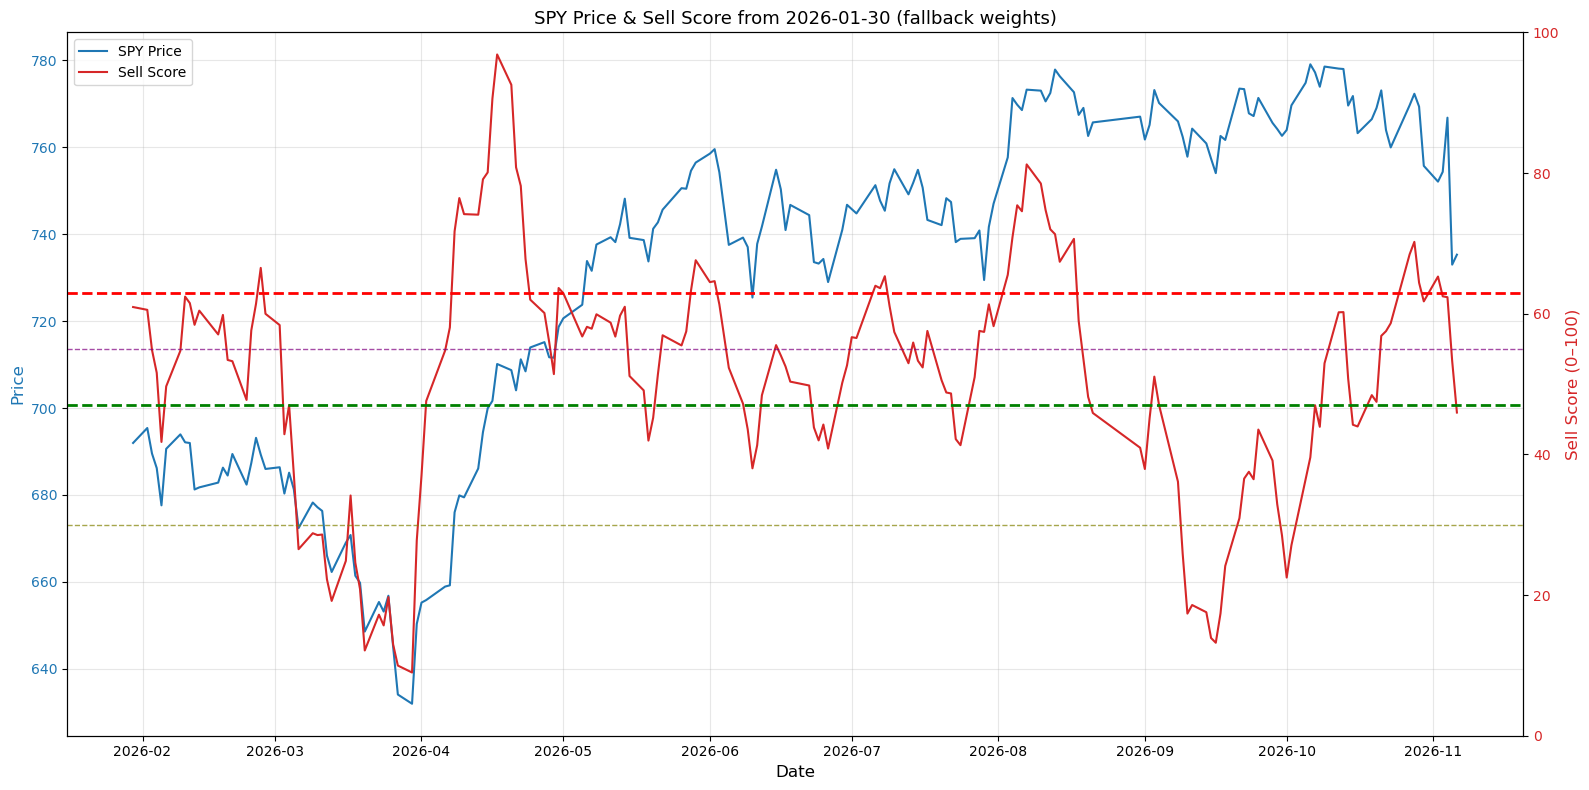

---- 
sell_score = 45.95 
---- 


<Figure size 640x480 with 0 Axes>

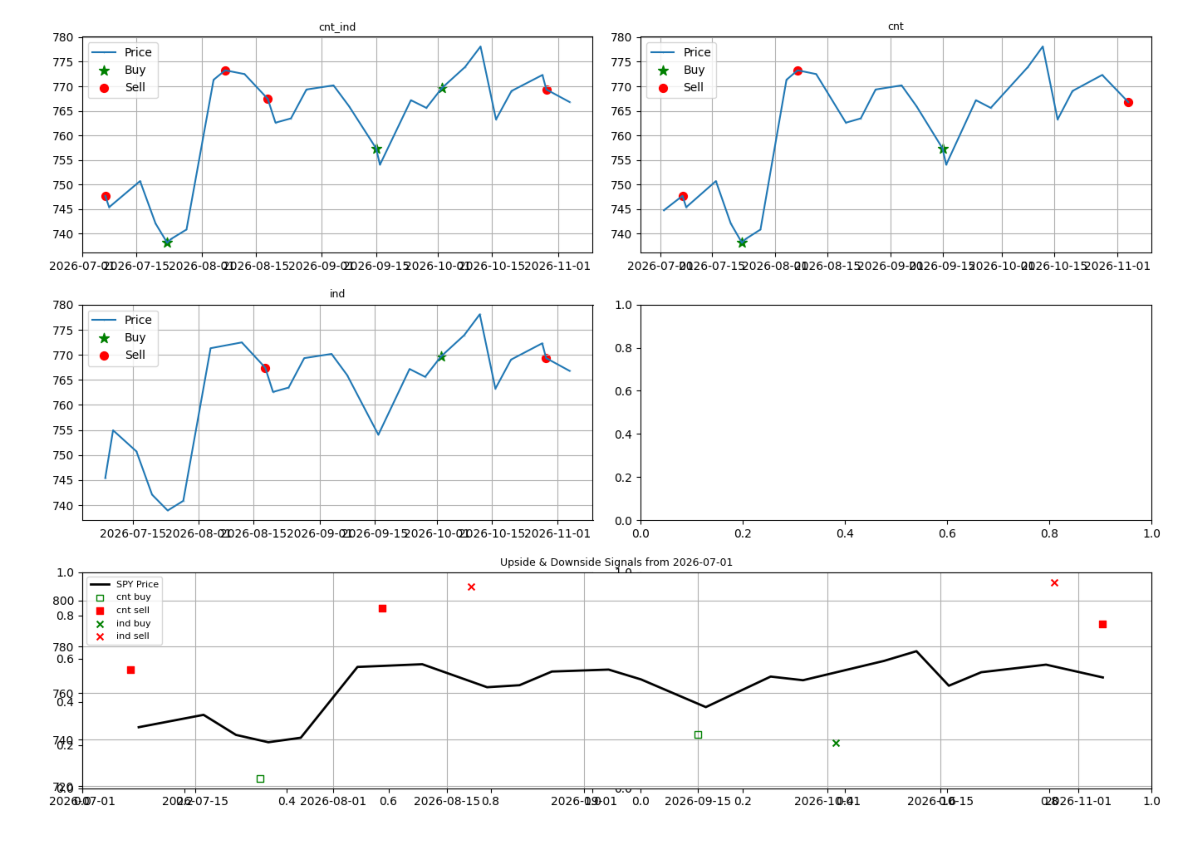

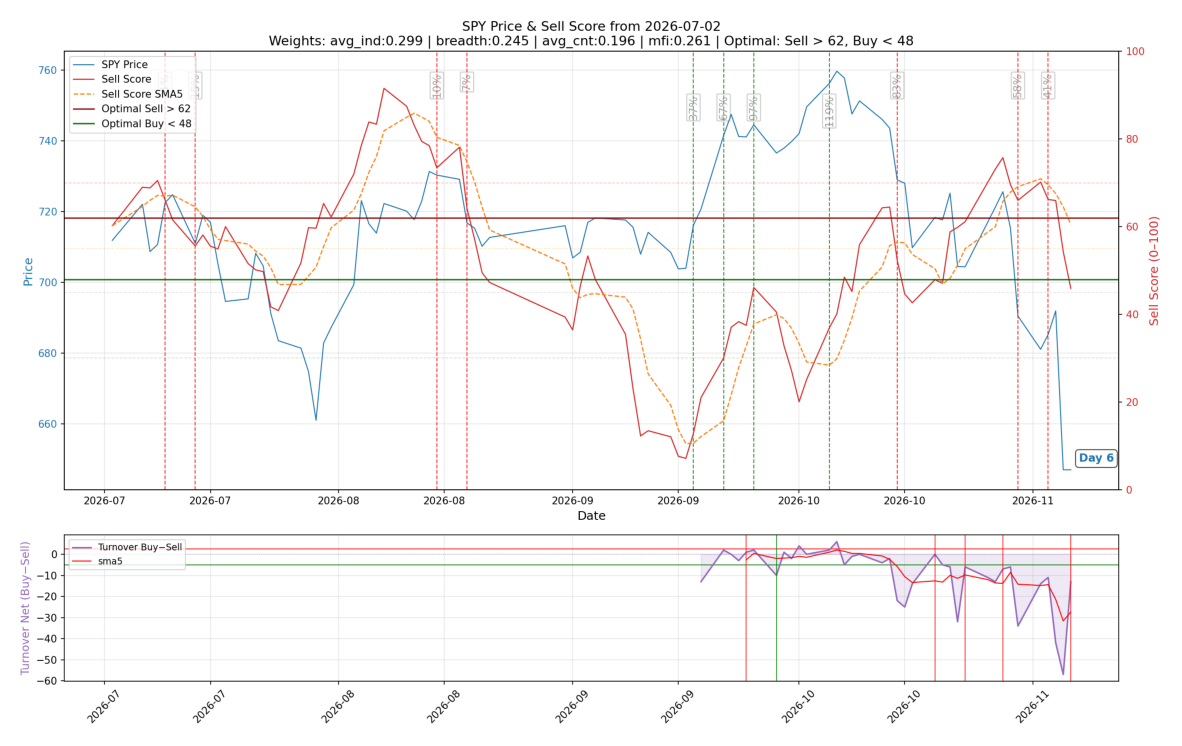

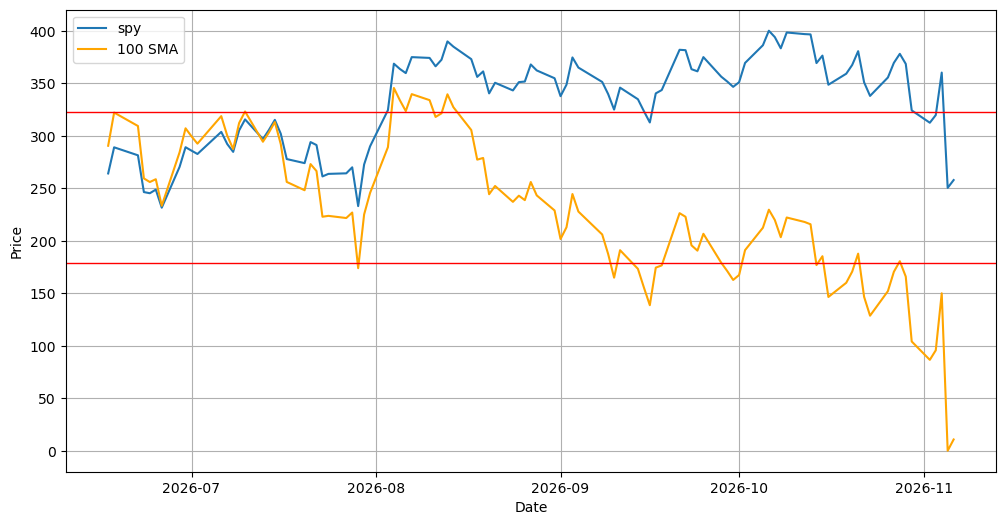

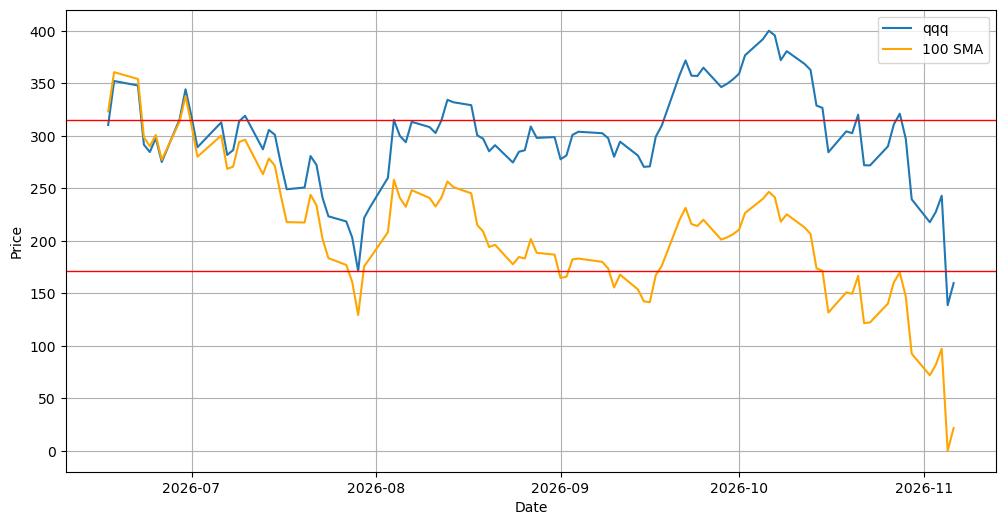

2026-11-05 00:00:00-06:00 - 28.360000610351562 - 25.687830077171323 - 29.3575200881958
2026-11-05 00:00:00-06:00 3
2026-11-06 00:00:00-06:00 - 27.760000228881836 - 25.754260075569153 - 29.43344008636475
2026-11-06 00:00:00-06:00 3


In [6]:
import mysql.connector
import pandas as pd
import numpy as np
import requests
from lxml import html
import re
import os
import seaborn  
import bezier
import math
import shutil

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from datetime import datetime, timedelta
import pytz

from skimage import io
import yfinance as yf

import configparser
config = configparser.ConfigParser()
config.read('config.ini')

TREND_DAY_COUNT = "60"
                    
def extraceText(text):
    string = str(text)
    result = re.search(r'\d+%', string).group()
    return result    


def fetch_alphaspread(etfName):
    site = "https://www.alphaspread.com/security/nasdaq/" + etfName.lower() + "/summary"
    
    try:
        page = requests.get(site)
        tree = html.fromstring(page.content)
        xpath = '//*[@id="main"]/div[3]/div[1]/div/div/div/div/div[2]/div[1]/div/div[3]/div[1]/div[1]/text()'
        data = tree.xpath(xpath)
#         print(data)
        dataNew = extraceText(data)
#         print("----------")
#         print(etfName + ", " + dataNew)
        print( dataNew)
    except AttributeError:
        print(".")
        
def getConnection():
    cnx = mysql.connector.connect(
#         host="lookupwd-24c.cz0e64ise636.us-east-1.rds.amazonaws.com",
#         host="novel9.czwuawkuwlbb.us-east-1.rds.amazonaws.com",
        
#         host="lookuwd-26.cw1w0ka6m85p.us-east-1.rds.amazonaws.com",
#         host="lookupwd-new26.ck3wisku88zi.us-east-1.rds.amazonaws.com",
        host=config['MySQL']['host'],
        user="novel",
        password="Test1234567",
        database="novel10"
    )
    return cnx
        
def insert(df, row):
    insert_loc = df.index.max()

    if pd.isna(insert_loc):
        df.loc[0] = row
    else:
        df.loc[insert_loc + 1] = row
        

        
def update_ticker_avg(avgValue, ctype, colname):
    # Create a datetime object representing the current date and time
    cnx = getConnection()
#     datetime_object = datetime.strptime(tickerDate, "%y%m%d")    

    # Create a cursor object to execute SQL queries
    cursor = cnx.cursor()

    # Execute a SQL query to retrieve data
    query = "select max(dateAdded) from ticker_spy"

    cursor.execute(query)
    result = cursor.fetchall()
    for i in result:
        now = i[0]
    cursor.close()

    # Format the datetime object as a string using the strftime() method
    date_string = now.strftime("%y%m%d")

    # Print the formatted date string
    # print(date_string)
    print(date_string + f" {ctype} : avg = " + str(avgValue))
    sql = "UPDATE ticker_spy set " + colname + " = %s WHERE ticker = %s and dateAdded = %s"
    cursorUpdate = cnx.cursor()  
    cursorUpdate.execute(sql, (avgValue, ctype, date_string))
    cursorUpdate.close()
    cnx.commit()
    cnx.close()
        
       
def get_up(cnx):
 # Create a cursor object to execute SQL queries
    cursor = cnx.cursor()    

    # Execute a SQL query to retrieve data
    query = "SELECT    DATE_FORMAT( tiv.dateAdded, '%m-%d'), "\
        "(countUp + countUp2) -  (countUp + countUp2)*(0.1+((countUp + countUp2) div 10)*0.02) AS diff_price , vix_pct"\
        "     FROM        ticker_up_down tiv "\
        "     WHERE          DATE(tiv.dateAdded) > DATE_SUB(CURDATE(), INTERVAL " + TREND_DAY_COUNT + " DAY) "\
        "     ORDER BY tiv.dateAdded ASC ";
                
    cursor.execute(query)

    df = pd.DataFrame(columns=['dateAdded', 'priceDiff', 'vix_pct'])
    # Fetch all rows from the result set and append them to the array
    for row in cursor.fetchall():
        insert(df,[row[0], float(row[1] or 0)])  
        
    # Close the cursor and connection
    cursor.close()
    return df

       
def get_down(cnx):
 # Create a cursor object to execute SQL queries
    cursor = cnx.cursor()    

    # Execute a SQL query to retrieve data
    query = "SELECT    DATE_FORMAT( tiv.dateAdded, '%m-%d'), "\
        " 0-(countDown -  countDown*(0.1+(countDown div 10)*0.02)) AS diff_price , vix_pct"\
        "     FROM        ticker_up_down tiv "\
        "     WHERE          DATE(tiv.dateAdded) > DATE_SUB(CURDATE(), INTERVAL " + TREND_DAY_COUNT + " DAY) "\
        "     ORDER BY tiv.dateAdded ASC ";
                
    cursor.execute(query)

    df = pd.DataFrame(columns=['dateAdded', 'priceDiff', 'vix_pct'])
    # Fetch all rows from the result set and append them to the array
    for row in cursor.fetchall():
        insert(df,[row[0], float(row[1] or 0)])  
        
    # Close the cursor and connection
    cursor.close()
    return df


def get_dip(cnx, ctype):
 # Create a cursor object to execute SQL queries
    cursor = cnx.cursor()    

    # Execute a SQL query to retrieve data
#     query = "SELECT  DATE_FORMAT( tiv.dateAdded, '%m-%d'), tiv.countUp / (tiv.countDown /2) AS diff_price "\
#         "     FROM        ticker_up_down tiv "\
#         "     WHERE          DATE(tiv.dateAdded) > DATE_SUB(CURDATE(), INTERVAL 25 DAY) "\
#         "     ORDER BY tiv.dateAdded ASC ";
    
#     query = "  SELECT dt,      tt.countDip "\
#        "    from (SELECT     DATE_FORMAT(tiv.dateAdded, '%m-%d') as dt, tiv.countDip "\
#          "   FROM    ticker_up_down tiv "\
#          "   WHERE    DATE(tiv.dateAdded) > DATE_SUB(CURDATE(), INTERVAL " + TREND_DAY_COUNT + " DAY)    ) tt ORDER BY dt ASC ";
               
    query = "    SELECT     dt, tt.countDip, tt.pp - 400 as price"\
        "  FROM    (SELECT         DATE_FORMAT(tiv.dateAdded, '%m-%d') AS dt,"\
        "             tiv.countDip,            ts.price  AS pp"\
        "     FROM        ticker_up_down tiv, ticker_spy ts"\
        "     WHERE        ts.ticker = 'SPY'"\
        "             AND tiv.dateAdded = ts.dateAdded"\
        "             AND DATE(ts.dateAdded) > DATE_SUB(CURDATE(), INTERVAL " + TREND_DAY_COUNT + " DAY)"\
        "             AND DATE(tiv.dateAdded) > DATE_SUB(CURDATE(), INTERVAL " + TREND_DAY_COUNT + " DAY)) tt ORDER BY dt ASC";

    cursor.execute(query)

    if (ctype == 1):
        df = pd.DataFrame(columns=['dateAdded', 'countDip'])
    
    if (ctype == 2):
        df = pd.DataFrame(columns=['dateAdded', 'price'])
        
    # Fetch all rows from the result set and append them to the array
    for row in cursor.fetchall():
        if (ctype == 1):
            insert(df,[row[0], float(row[1] or 0)])  
        if (ctype == 2):
            insert(df,[row[0], float(row[2] or 0)])  
        
    # Close the cursor and connection
    cursor.close()
    return df

def get_up_down(cnx):
 # Create a cursor object to execute SQL queries
    cursor = cnx.cursor()    

    # Execute a SQL query to retrieve data
#     query = "SELECT  DATE_FORMAT( tiv.dateAdded, '%m-%d'), tiv.countUp / (tiv.countDown /2) AS diff_price "\
#         "     FROM        ticker_up_down tiv "\
#         "     WHERE          DATE(tiv.dateAdded) > DATE_SUB(CURDATE(), INTERVAL 25 DAY) "\
#         "     ORDER BY tiv.dateAdded ASC ";
#        "     CASE        WHEN tiv.countUp > 50 THEN tiv.countUp / 2        ELSE tiv.countUp    END as cntup, "\
#        "     CASE        WHEN tiv.countDown > 50 THEN tiv.countDown / 2        ELSE tiv.countDown    END  as cntdown "\
    
    query = "  SELECT dt,     tt.cntup / tt.cntdown AS diff_price , vix_pct "\
       "    from (SELECT     DATE_FORMAT(tiv.dateAdded, '%m-%d') as dt, "\
         " (countUp + countUp2) -  (countUp + countUp2)*(0.1+((countUp + countUp2) div 10)*0.02) as cntup, "\
       " countDown -  countDown*(0.1+(countDown div 10)*0.02) as cntdown , vix_pct"\
         "   FROM    ticker_up_down tiv "\
         "   WHERE    DATE(tiv.dateAdded) > DATE_SUB(CURDATE(), INTERVAL " + TREND_DAY_COUNT + " DAY)    ) tt ORDER BY dt ASC ";
                
    cursor.execute(query)

    df = pd.DataFrame(columns=['dateAdded', 'priceDiff', 'vix_pct'])
    # Fetch all rows from the result set and append them to the array
    for row in cursor.fetchall():
        insert(df,[row[0], float(row[1] or 0),  float(row[2] or 0)])  
        
    # Close the cursor and connection
    cursor.close()
    return df
        
def get_spy_data(cnx, tickerName, ctype):
 # Create a cursor object to execute SQL queries
    cursor = cnx.cursor()
        

    # Execute a SQL query to retrieve data
#     query = "SELECT  DATE_FORMAT(z.prev_date_add, '%m-%d')  as dateAdded2 , "\
    query = "SELECT   DATE_FORMAT(z.dateAdded, '%m-%d')   as dateAdded2 , "\
        " z.price - z.prev_price AS diff_price, z.price"\
        " FROM    (SELECT         dateAdded, price, CAST(prev_action AS CHAR) AS prev_price, CAST(prev_date AS DATE) AS prev_date_add "\
        "     FROM        (SELECT         y.*, @prev AS prev_action, @prev:=price, @prev2 AS prev_date, @prev2:=dateAdded "\
        "     FROM        (SELECT         tiv.dateAdded, tiv.price "\
        "     FROM        ticker_spy tiv "\
        "     WHERE        tiv.ticker = %(index_name)s    AND DATE(tiv.dateAdded) > DATE_SUB(CURDATE(), INTERVAL " + TREND_DAY_COUNT + " DAY) "\
        "     ORDER BY tiv.dateAdded ASC) y, (SELECT @prev:=NULL) vars  , (SELECT @prev2:=NULL) vars2  ORDER BY dateAdded) x) z ";
                

    cursor.execute(query, {'index_name': tickerName})

    if (ctype == 1):
        df = pd.DataFrame(columns=['dateAdded', 'priceDiff'])
    if (ctype == 2):
        df = pd.DataFrame(columns=['dateAdded', 'price'])
    # Fetch all rows from the result set and append them to the array
    for row in cursor.fetchall():
        if (ctype == 1):
            insert(df,[row[0], float(row[1] or 0)])  
        if (ctype == 2):
            insert(df,[row[0], float(row[2] or 0)])  

    # Close the cursor and connection
    cursor.close()
    return df

def getDf(upType):
    cnx = getConnection();
    # Sample data
    
    df1 = get_spy_data(cnx, 'SPY', 1)
    if upType == 1:
        df2 = get_up(cnx)        
    if upType == 2:
        df2 = get_down(cnx)
    if upType == 3:
        df2 = get_up_down(cnx)
    if upType == 4:
        df2 = get_up_down(cnx)
        df3 = get_dip(cnx, 1)
        df4 = get_spy_data(cnx, 'SPY', 2)
    
    
#     print(df1)
#     print(df2)
    cnx.close()
    
    last_date = df2.iloc[-1].values[0]
    last_price = df1.iloc[-1].values[1]
    
#     print(last_price)
    
#     new_row = pd.Series([last_row['dateAdded'], 0], index=df1.columns)  # or use a dictionary: {'Name': 'Dave', 'Age': 40}
#     new_row = {'dateAdded': last_row['dateAdded'],  'priceDiff': 0}
#     df1 = pd.concat([df1, new_row], ignore_index=True)

    isPiror = False
    if isPiror:
        insert(df1,[last_date, float(last_price)])  

        if upType == 4:
            insert(df4,[last_date, float(df4.iloc[-1].values[1])])  
    
 # Create data frames from the arrays
     # Merge the data frames on the 'Date' column
    
    if upType != 4:
        df = pd.merge(df1, df2, on='dateAdded')
        
    if upType == 4:
        dftemp = pd.merge(df1, df2, on='dateAdded')        
        dftemp2 = pd.merge(dftemp,df3,on='dateAdded')  
        df = pd.merge(dftemp2,df4,on='dateAdded')
 
    # Concatenate the new row with the existing data frame
#     df = pd.concat([df, new_row.to_frame().T], ignore_index=True)
#     new_row = {'dateAdded': last_row['dateAdded'],  'priceDiff_y': float(last_row['priceDiff'])}
#     pd.concat([new_row,df.loc[:]]).reset_index(drop=True)
    # Append the new row to the data frame
#     df = df.append(new_row)
    print(df.tail(5))
    return df


def showCorrBad(df):
    
    fig, [ax1, ax2] = plt.subplots(2, 1, sharex=True)
#     ax1.xcorr(df['priceDiff_x'], df['priceDiff_y'], usevlines=True, maxlags=50, normed=True, lw=2)
#     ax1.grid(True)

    ax2.acorr(df['priceDiff_x'], usevlines=True, normed=True, maxlags=50, lw=2)
    ax2.grid(True)
    
def calculate_sma(df, window_size=4, band_size=3):
    df['sma_sma3'] = df['upDownCnt'].rolling(window=window_size).mean()
    df['sma_h3'] = df['sma_sma3'] + band_size
    df['sma_l3'] = df['sma_sma3'] - band_size

    return df


        
def update_count_avg(avgValue):
    # Create a datetime object representing the current date and time
    cnx = getConnection()
#     datetime_object = datetime.strptime(tickerDate, "%y%m%d")    

    # Create a cursor object to execute SQL queries
    cursor = cnx.cursor()

    # Execute a SQL query to retrieve data
    query = "select max(dateAdded) from ticker_up_down"

    cursor.execute(query)
    result = cursor.fetchall()
    for i in result:
        now = i[0]
    cursor.close()

    # Format the datetime object as a string using the strftime() method
    date_string = now.strftime("%y%m%d")

    # Print the formatted date string
    # print(date_string)
    print(date_string + "update_count_avg : avg = " + str(avgValue))
    sql = "UPDATE ticker_up_down set count_avg = %s WHERE dateAdded = %s"
    cursorUpdate = cnx.cursor()  
    cursorUpdate.execute(sql, (avgValue, date_string))
    cursorUpdate.close()
    cnx.commit()
    cnx.close()
    
def get_sql_buy_score():
    return """
        SELECT
            s.dateAdded,
            s.price,
            s.avg2 AS avg_ind,
            tud.count_avg AS avg_cnt,
            mfi.trend AS mfi,
            br.trend AS breadth
        FROM ticker_spy s
        LEFT JOIN ticker_up_down tud ON DATE(s.dateAdded) = DATE(tud.dateAdded)
        LEFT JOIN ticker_indicator mfi ON DATE(s.dateAdded) = DATE(mfi.dateAdded) AND mfi.tickername = 'MFI'
        LEFT JOIN ticker_indicator br ON DATE(s.dateAdded) = DATE(br.dateAdded) AND br.tickername = 'breadth'
        WHERE s.ticker = 'SPY'
        AND DATE(s.dateAdded) >= %(start_date)s
        ORDER BY s.dateAdded
    """

def get_buy_score(dateStr, sell_weights=None):
    """Generate buy / sell scores based on weighted combination of indicators.

    Buy Score uses fixed weights:
        0.40 × avg_ind + 0.30 × Breadth + 0.20 × avg_cnt + 0.10 × MFI

    Sell Score uses dynamic weights from calc_sell_score_weights() when
    available (historical drop-probability → normalized), otherwise falls
    back to fixed weights.

    Each component is normalized to 0-100 scale via min-max over the
    queried date range before applying weights.
    """
    cnx = getConnection()
    try:
        datetime_object = datetime.strptime(dateStr, "%Y-%m-%d")
        cursor = cnx.cursor()
        cursor.execute(get_sql_buy_score(), {'start_date': datetime_object})
        rows = cursor.fetchall()
        cursor.close()

        if not rows:
            writefile("No buy score data found")
            return None

        df = pd.DataFrame(rows, columns=['dateAdded', 'price', 'avg_ind', 'avg_cnt', 'mfi', 'breadth'])
        df['dateAdded'] = pd.to_datetime(df['dateAdded'])

        # Convert to numeric
        for col in ['price', 'avg_ind', 'avg_cnt', 'mfi', 'breadth']:
            df[col] = pd.to_numeric(df[col], errors='coerce')

        # Drop rows where any indicator is NaN
        df = df.dropna(subset=['avg_ind', 'avg_cnt', 'mfi', 'breadth'])

        if len(df) == 0:
            writefile("No complete buy score data after cleaning")
            return None

        # Normalize each component to 0-100 scale using min-max
        def normalize_0_100(series):
            mn = series.min()
            mx = series.max()
            if mx == mn:
                return pd.Series([50.0] * len(series), index=series.index)
            return ((series - mn) / (mx - mn)) * 100

        df['avg_ind_norm'] = normalize_0_100(df['avg_ind'])
        df['breadth_norm'] = normalize_0_100(df['breadth'])
        df['avg_cnt_norm'] = normalize_0_100(df['avg_cnt'])
        df['mfi_norm'] = normalize_0_100(df['mfi'])


        # Compute sell score — use dynamic weights when available
        if sell_weights is not None:
            w = sell_weights
            df['sell_score'] = (
                w['avg_ind']   * df['avg_ind_norm'] +
                w['breadth']   * df['breadth_norm'] +
                w['avg_cnt']   * df['avg_cnt_norm'] +
                w['mfi']       * df['mfi_norm']
            )
        else:
            # Fallback fixed weights
            df['sell_score'] = (
                0.35 * df['avg_ind_norm'] +
                0.20 * df['avg_cnt_norm'] +
                0.30 * df['breadth_norm'] +
                0.15 * df['mfi_norm']
            )
        pd.set_option('display.max_columns', None)
        pd.set_option('display.width', 200)
        pd.set_option('display.max_colwidth', 15)
        latest = df.tail(5)[['dateAdded', 'price', 'avg_ind_norm', 'breadth_norm', 'avg_cnt_norm', 'mfi_norm',  'sell_score']].copy()
        latest['dateAdded'] = latest['dateAdded'].dt.strftime('%Y-%m-%d')
        for col in ['price', 'avg_ind_norm', 'breadth_norm', 'avg_cnt_norm', 'mfi_norm',  'sell_score']:
            latest[col] = latest[col].round(2)
        writefile(latest.to_string(index=False))
        return df

    except Exception as e:
        writefile(f"Unable to get_buy_score")
        writefile(e)
        return None
    finally:
        cnx.close()
        


def _draw_score_chart(df, dateStr, sell_weights=None):
    """Draw dual-axis chart: SPY price (left axis) + sell_score (right axis).

    Saves to chart_score_<dateStr>.png.
    """
    import matplotlib.dates as mdates

    df = df.sort_values('dateAdded').copy()

    _, ax1 = plt.subplots(figsize=(16, 8))

    # Price line (left axis)
    ax1.plot(df['dateAdded'], df['price'], label='SPY Price', linewidth=1.5, color='#1f77b4')
    ax1.set_xlabel('Date', fontsize=12)
    ax1.set_ylabel('Price', fontsize=12, color='#1f77b4')
    ax1.tick_params(axis='y', labelcolor='#1f77b4')

    # Sell score line (right axis)
    ax2 = ax1.twinx()
    ax2.plot(df['dateAdded'], df['sell_score'], label='Sell Score', linewidth=1.5, color='#d62728')
    ax2.set_ylabel('Sell Score (0–100)', fontsize=12, color='#d62728')
    ax2.tick_params(axis='y', labelcolor='#d62728')
    ax2.set_ylim(0, 100)

    # Threshold lines for sell score
    sell_point = 63    
    buy_point = 47
    print(f"{sell_point} - {buy_point}")
    ax2.axhline(y=sell_point, color='red', linestyle='--', linewidth=2, alpha=1)
    ax2.axhline(y=55, color='purple', linestyle='--', linewidth=1, alpha=0.7)
    ax2.axhline(y=buy_point, color='green', linestyle='--', linewidth=2, alpha=1)
    ax2.axhline(y=30, color='olive', linestyle='--', linewidth=1, alpha=0.7)

    # Title with weight info
    if sell_weights is not None:
        weight_str = " | ".join(f"{k}:{v:.3f}" for k, v in sell_weights.items())
        title = f'SPY Price & Sell Score from {dateStr}\nWeights: {weight_str}'
    else:
        title = f'SPY Price & Sell Score from {dateStr} (fallback weights)'
    ax1.set_title(title, fontsize=13)

    # Combined legend
    lines1, labels1 = ax1.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()
    ax1.legend(lines1 + lines2, labels1 + labels2, fontsize=10, loc='upper left')

    ax1.grid(True, alpha=0.3)
    ax1.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
    plt.xticks(rotation=45)
    plt.tight_layout()

    chart_file = f'chart_score_{dateStr}.png'
    
    plt.savefig(chart_file, dpi=150)
    writefile(f"Score chart saved as {chart_file}")
    plt.show()
    plt.close()


def get_sql_buy_score():
    return """
        SELECT
            s.dateAdded,
            s.price,
            s.avg2 AS avg_ind,
            tud.count_avg AS avg_cnt,
            mfi.trend AS mfi,
            br.trend AS breadth
        FROM ticker_spy s
        LEFT JOIN ticker_up_down tud ON DATE(s.dateAdded) = DATE(tud.dateAdded)
        LEFT JOIN ticker_indicator mfi ON DATE(s.dateAdded) = DATE(mfi.dateAdded) AND mfi.tickername = 'MFI'
        LEFT JOIN ticker_indicator br ON DATE(s.dateAdded) = DATE(br.dateAdded) AND br.tickername = 'breadth'
        WHERE s.ticker = 'SPY'
        AND DATE(s.dateAdded) >= %(start_date)s
        ORDER BY s.dateAdded
    """


def get_sql_by_score():
    """SQL query for sell score weight backtest — same as get_sql_buy_score().

    Returns daily: dateAdded, price, avg_ind, avg_cnt, mfi, breadth for SPY.
    """
    return get_sql_buy_score()


def calc_sell_score_weights(dateStr, lookback_years=0.8, forward_days=10, percentile=70):
    """Calculate normalized sell-score weights from historical performance.

    For each indicator over the past `lookback_years`:
    1. Flag days where indicator > its rolling 252-day `percentile` threshold
       (an "overbought / sell signal" condition).
    2. Check if SPY price is lower `forward_days` trading days later.
    3. Drop probability = drops / total signals.
    4. Normalize all four probabilities so weights sum to 1.

    Returns (weights, drop_probs, signal_counts) — three dicts keyed by
    indicator name.  Returns None tuples on error / insufficient data.
    """
    cnx = getConnection()
    try:
        end_date = datetime.strptime(dateStr, "%Y-%m-%d")
        start_date = end_date - timedelta(days=int(lookback_years * 365))

        cursor = cnx.cursor()
        cursor.execute(get_sql_by_score(), {'start_date': start_date})
        rows = cursor.fetchall()
        cursor.close()

        if not rows:
            writefile("calc_sell_score_weights: no data")
            return None, None, None

        df = pd.DataFrame(rows, columns=['dateAdded', 'price', 'avg_ind', 'avg_cnt', 'mfi', 'breadth'])
        df['dateAdded'] = pd.to_datetime(df['dateAdded'])
        for col in ['price', 'avg_ind', 'avg_cnt', 'mfi', 'breadth']:
            df[col] = pd.to_numeric(df[col], errors='coerce')
        df = df.dropna(subset=['price', 'avg_ind', 'avg_cnt', 'mfi', 'breadth'])
        df = df.sort_values('dateAdded').reset_index(drop=True)

        if len(df) < 50:
            writefile(f"calc_sell_score_weights: only {len(df)} rows, need >= 252")
            return None, None, None

        indicators = ['avg_ind', 'breadth', 'avg_cnt', 'mfi']
        drop_probs = {}
        signal_counts = {}

        window = 252       # 1-year rolling
        min_periods = 126  # need at least half a year before emitting signals

        for indicator in indicators:
            rolling_threshold = (
                df[indicator]
                .rolling(window, min_periods=min_periods)
                .quantile(percentile / 100.0)
            )

            signals = 0
            drops = 0

            for i in range(len(df) - forward_days):
                thresh = rolling_threshold.iloc[i]
                if pd.isna(thresh):
                    continue
                if df[indicator].iloc[i] > thresh:
                    signals += 1
                    if df['price'].iloc[i + forward_days] < df['price'].iloc[i]:
                        drops += 1

            prob = drops / signals if signals > 0 else 0.0
            drop_probs[indicator] = prob
            signal_counts[indicator] = signals

        total = sum(drop_probs.values())
        if total == 0:
            writefile("calc_sell_score_weights: all probs zero")
            return None, None, None

        weights = {k: v / total for k, v in drop_probs.items()}

        # Print the weight table
        writefile("")
        writefile(f"=== Sell Score Weights (past {lookback_years}y, >P{percentile}, {forward_days}d forward) ===")
        writefile(f"{'Indicator':<12} {'Sell后天下跌概率':<22} {'Signals':<10} {'Weight':<10}")
        writefile("-" * 54)
        for ind in indicators:
            writefile(f"{ind:<12} {drop_probs[ind]*100:.0f}%{'':<17} {signal_counts[ind]:<10} {weights[ind]:.3f}")
        writefile(f"{'Sum':<12} {'':<22} {'':<10} {sum(weights.values()):.3f}")
        writefile("")
        writefile("sell_score = " + " + ".join(f"{weights[ind]:.3f} * {ind}" for ind in indicators))

        return weights, drop_probs, signal_counts

    except Exception as e:
        writefile(f"calc_sell_score_weights error: {e}")
        return None, None, None
    finally:
        cnx.close()
        
def writefile(msg):   
    print(msg)

def showScore():   
    dateStr = datetime.now().strftime("%Y-%m-%d")
    startdateStr = (datetime.now() - timedelta(days=280)).strftime("%Y-%m-%d")
    sell_weights, _drop_probs, _signal_counts = calc_sell_score_weights(dateStr, forward_days=10)
    if sell_weights is not None:
        writefile("=== Sell Score (dynamic weights from 1-year history) ===")
    else:
        writefile("=== Sell Score (fallback fixed weights) ===")
    df_buy_score = get_buy_score(startdateStr, sell_weights)
    
    _draw_score_chart(df_buy_score, startdateStr)
    print(f"---- ")
    if df_buy_score is not None and len(df_buy_score) > 0:

        # Latest score summary
        last_row = df_buy_score.iloc[-1]
        sell_score = last_row['sell_score']
        print(f"sell_score = {sell_score:.2f} ")
        print(f"---- ")
        
def showTrend(df, windowSize):

    
    fig, ax = plt.subplots(figsize=(8, 6))
    
    # df.dateAdded = df.dateAdded.dt.date
    df['priceDiff_x']=df['priceDiff_x'].astype(float) * 2
    
    
    line, = ax.plot(df['dateAdded'],df['priceDiff_x'], color='azure', linewidth = 0.3, linestyle='dotted')
    line.set_label('diff')
    
    
    df['vix_pct']=df['vix_pct'].astype(float)    
    df['vix_pct'] = df['vix_pct'].replace(0, np.nan)
    line, = ax.plot(df['dateAdded'],df['vix_pct'], color='red', marker='o', linewidth = 1, linestyle='-')
    line.set_label('vix')
        
    numbers=df['priceDiff_y'].astype(float)
    avgNum2 =  np.mean(numbers)    
#     print("avgNum2 - " + str(avgNum2))
    avgNum =  8
    newNumbers = [ (x * avgNum) - avgNum  if x < 1 else (x-1)/2 for x in numbers]      
    
    newNumberDown = [k for k in newNumbers if k <= 0]
    avgnewNumbers =  float(np.mean(newNumberDown))
    update_ticker_avg(avgnewNumbers, 'QQQ', 'avg')
    
#     if math.isnan(avgnewNumberUp):
    newNumberUp = [k for k in newNumbers if k > 0]
    
    if len(newNumberUp) > 0:
        avgnewNumberUp =  float(np.mean(newNumberUp))
        update_ticker_avg(avgnewNumberUp, 'IWM', 'avg')  
    else:
        avgnewNumberUp = 0
        update_ticker_avg(avgnewNumberUp, 'IWM', 'avg')  
        
    plt.axhline(y=avgnewNumberUp, color='purple', linestyle='-.', linewidth = 1.5)
        
    df['upDownCnt'] = newNumbers
#     newNumbers = numbers
#     print(numbers)
    print(newNumbers[-5:])
    line, = ax.plot(df['dateAdded'],newNumbers, color='magenta', linewidth = 0.6) 
    line.set_label('upDownCnt')
    
    df['countDip']=df['countDip'].astype(float) / 4
    line, =ax.plot(df['dateAdded'],df['countDip'], color='azure', linewidth = 0.6)    
    line.set_label('Dip')

    df['price']=df['price'].astype(float) 
    avgPrice =  float(np.mean(df['price']))
#     windowSize=5
    df['price']=(df['price'] - avgPrice)/2.5
    df = calculate_sma(df, windowSize)
    
    
    last_sma_value = (df['sma_sma3'].iloc[-1].astype(float) ) 
    print("last_sma_value - " + str(last_sma_value))
    update_count_avg(float(last_sma_value))
    
    ax.plot(df.dateAdded,df['sma_h3'], ls='dashed', color="grey",  linewidth=0.5)
    ax.plot(df.dateAdded,df['sma_l3'], ls='dashed', color="grey",  linewidth=0.5)
    ax.plot(df.dateAdded,df['sma_sma3'], ls='dashed', color="blue",  linewidth=2)        
    plt.fill_between(df.dateAdded, df['sma_h3'], df['sma_l3'], 
                     where=(df['sma_l3'] < df['sma_h3']), interpolate=True, color='lightblue', alpha=0.2)

    line, = ax.plot(df['dateAdded'],df['price'], color='green', linestyle='dotted', linewidth = 3)      
    line.set_label('price')
    
#     plt.legend(['priceDiff', 'upDownCnt',  'Dip', 'Price'], loc='upper left')
    plt.legend(loc='upper left')
    
    
#     xticks(ax,[1 2 3])
#     xticklabels(ax,df['dateAdded'])
    
    ax.xaxis.label.set_size(5)
    ax.xaxis.set_tick_params(labelsize='xx-small')
    
    date_form = mdates.DateFormatter('%m%d')
#     ax.xaxis.set_major_formatter(date_form)     
    tick_spacing = 3
    ax.xaxis.set_major_locator(ticker.MultipleLocator(tick_spacing))  
    
    avgNumDiff =  np.mean(df['priceDiff_x'])   
    avgNumUpDown =  np.mean(newNumberDown)   
    
    plt.axhline(y=0, color='r', linestyle='-.', linewidth = 0.5)
    plt.axhline(y=avgNumDiff, color='brown', linestyle='dotted', linewidth = 2)
    plt.axhline(y=avgNumUpDown, color='purple', linestyle='-', linewidth = 1.5)
#     plt.axhline(y=avgNum, color='b', linestyle='--', linewidth = 1)

        # Set title and labels for axes
#     ax.set(xlabel="Date",
#     #            ylabel="price",
#            title=" indicator")
    
    plt.gcf().set_size_inches((10, 6)) 
    plt.ylim(-15, 15)  # Sets the maximum value of the x-axis to 6
    plt.grid(axis='x', linewidth=0.3)
    plt.subplots_adjust(wspace=None, hspace=None)
    plt.savefig('indicator-cnt-updown.png')
#     fig, ax3 = plt.subplots(figsize=(11.71, 15)) 
    plt.show()
    
#     ax3.imshow(image2[height2//2:, 98:])

    image2 = mpimg.imread("indicator-mrp.png")
    height2, width2 = image2.shape[0], image2.shape[1]
    plt.subplots_adjust(wspace=None, hspace=None)
    fig, ax2 = plt.subplots(figsize=(11.71, 15)) 
#     fig, ax2 = plt.subplots(figsize=(11.71, 28)) 
    ax2.set_title('')
    ax2.axis('off')
    ax2.imshow(image2[height2//2:, 98:])
    
    image1 = mpimg.imread("indicator-spy.png")
    
   
#     print("indicator - spy")
    # Get the height and width of the image
    height1, width1 = image1.shape[0], image1.shape[1]
    plt.subplots_adjust(wspace=None, hspace=None)
    fig, ax = plt.subplots(figsize=(11.71, 22)) 
#     fig, ax = plt.subplots(figsize=(18, 15)) 
    ax.set_title('')
    ax.axis('off')
#     ax.imshow(image1[height1//2+350:, 98:])
    ax.imshow(image1[height1//2+100:, 98:])
#     plt.show()

#     print("indicator - mrp")
    

#     ax2.imshow(image2[height2:, 98:])
    plt.show()
    createNewFile("indicator-spy.png")
    createNewFile("indicator-mrp.png")
    createNewFile("indicator-cnt-updown.png")
    


def get_vix_sma200_pct_times():
    ticker = "^VIX"
    df = yf.Ticker(ticker).history(period="2y")

    df['SMA_200'] = df['Close'].rolling(window=200).mean()
    rate = 1.4

    # Calculate the threshold (30% above SMA)
    df['Threshold'] = df['SMA_200'] * rate

    # Find dates where VIX price is greater than the threshold
    result = df[df['High'] > df['Threshold']]

    five_days_ago =datetime.today() - timedelta(days=3)
    five_days_ago = five_days_ago.replace(tzinfo=pytz.timezone('America/Chicago'))

    # Filter rows where the date is within the past 5 days
    recent_data = result[result.index > five_days_ago]

    # Display the dates and corresponding VIX prices

    cnx = getConnection()
    # print(result)

    try:
        for date, row in recent_data.iterrows():
            
            timestamp_str = date.strftime('%Y-%m-%d')
            valueInt = 0
            high =  row['High']
            threshold_1 = row['SMA_200'] * 1.4
            threshold_2 = row['SMA_200'] * 1.6
            print(f"{date} - {high} - {threshold_1} - {threshold_2}")
            # datetime_object = datetime.strptime(date, "%y%m%d")
            # query = "update  ticker_overvalue set tickerValue =  %(ticker_value)s WHERE DATE(dateAdded) >= %(index_date)s and tickerName = %(ticker_name)s"
            query = "update  ticker_up_down set vix_pct =  %s WHERE DATE(dateAdded) = %s "

            if high > threshold_2:
                valueInt = 5
            elif high > threshold_1:
                valueInt = 3
            if valueInt > 0:
                print(f"{date} {valueInt}")
                cursorUpdate = cnx.cursor();
                cursorUpdate.execute(query,
                                     (valueInt, timestamp_str));
                cursorUpdate.close()
        cnx.commit()
    except Exception as e:
        print("Unable to load set vix pct")
        print(e)
    finally:
        cnx.close()
    
def createNewFile(file_to_move):

    # Get the current year and month
    current_year = datetime.now().year
    current_month = datetime.now().month
    
#     if current_month % 2 != 0:
#         return

    # Create the folder with the current year if it doesn't exist
    folder_name = str(current_year)
    if not os.path.exists(folder_name):
        os.makedirs(folder_name)


    # Extract the file name and extension
    file_name, file_extension = os.path.splitext(file_to_move)

    # Create the new file name with the current month appended
    new_file_name = f"{file_name}_{current_month}{file_extension}"    
    
        
    if not os.path.exists(os.path.join(folder_name, new_file_name)): 

        # copy the file to the new folder with the new name
        shutil.copy(file_to_move, os.path.join(folder_name, new_file_name))

        print(f"File moved to {folder_name}/{new_file_name}")
#     else:        
#         print(f"File existed {folder_name}/{new_file_name}")


    
    
def showCorr(dataframe):
    
    
    correlation = dataframe.corr ()  
#     heatmap = seaborn. heatmap(correlation)  
    heatmap = seaborn. heatmap(correlation, annot = True)  
#     heatmap.set (xlabel = 'SPY',ylabel = 'UpDown', title = "Correlation")  
    plt.show ()  
    
# your function
def f(t): 
    return np.sin(t)

def makeArrow(ax,pos,function,direction):
    delta = 0.0001 if direction >= 0 else -0.0001
    ax.arrow(pos,function(pos),pos+delta,function(pos+delta),head_width=0.05,head_length=0.2)

def addCruve(df, csize, offset, ax, cl ):
#     50:55
    totalSize = df['priceDiff_x'].size
    startPos = totalSize - csize * offset    
    endPos = totalSize - csize * (offset - 1)
    if (offset > 1):
        startPos = startPos + offset - 1
        endPos = endPos + offset - 1
#     print(str(startPos) + "  - " + str(endPos))    
    dfx=df['priceDiff_x'][startPos:endPos]
    dfy=df['priceDiff_y'][startPos:endPos]    
    nodes1 = np.asfortranarray([dfx, dfy])
    dfSize = csize - 1
    curve1 = bezier.Curve(nodes1, degree=dfSize)
#     return curve1
#     curve1 = addCruve(df, csize, 1, ax)   
    curve1.plot(100, ax=ax, alpha=None, color=cl)
    
#     fig = plt.gcf();
#     ax = fig.add_subplot();

#     ax = curve1.plot(100, color='r', alpha=None, ax=None)


#     fig = subplots(rows=2, cols=2, shared_yaxes=True)
#     fig, ax = plt.subplots()
#     figName = 'fig' + str(offset)
#     f[f['figure'] == figName].plot(ax=fig, x='x_axis', y='y_axis', legend=False)
#     f[f['figure'] == 'fig2'].plot(ax=fig, x='x_axis', y='y_axis', legend=False)
   
    
def addCruveAll(df, csize):
    
    fig = plt.gcf();
    ax = fig.add_subplot();
#     set(gca,'LineWidth',2)
#     hline = findobj(fig, 'type', 'line');
#     set(hline,'LineWidth',2);
#     fig = gcf 
#     ax = get(fig,'children') 
#     h = get(ax,'children') 
#     set(h,'LineWidth',3)

#     set(plt,{'LineWidth'},{5})
    addCruve(df, csize, 1, ax, 'purple')
    addCruve(df, csize, 2, ax, 'tomato')
    addCruve(df, csize, 3, ax, 'coral')
    addCruve(df, csize, 4, ax, 'lightcoral')
    
    
#     addCruve(df, csize, 2, ax, 'plum')
#     addCruve(df, csize, 3, ax, 'plum')
#     addCruve(df, csize, 4, ax, 'wheat')
#     addCruve(df, csize, 4, ax, 'plum')


    
#     curve2 = addCruve(df, csize, 2)
    
#     gsdict={'height_ratios':[1, 4]}
#     fig, (ax1, ax2) = plt.subplots(1, 1, sharex=True)
#     ax1, ax2 = plt.subplots(2, 1, sharey=True,sharex=True)
#     curve1.plot(100, ax=ax1)
#     curve2.plot(100, ax=ax2)

#     ax3 = fig.add_subplot(111, facecolor="none")
#     ax3.yaxis.set_label_position("right")

#     ax3.tick_params(left=False, right=True, labelleft=False, labelright=True,
#                     bottom=False, labelbottom=False)
#     ax1.get_shared_x_axes().join(ax1,ax3)
    


    
def showchart(df, upType, avgNum, csize):
    
    if avgNum > 1:        
        numbers=df['priceDiff_y'].astype(float)
        df['priceDiff_y'] = [(x * avgNum)  if x < 1 else avgNum + (x-1)/2 for x in numbers]        
        
    addCruveAll(df, csize)
    
    
#     plt.figure(figsize=(40,40))
    plt.scatter(df['priceDiff_x'], df['priceDiff_y'], s=5)

#     plt.axvline(x=0, color='r', linestyle='-', linewidth = 0.5)

    avgNumX =  np.mean(df['priceDiff_x'])   
    plt.axvline(x=avgNumX, color='r', linestyle='-', linewidth = 0.5)
    plt.axvline(x=0, color='wheat', linestyle='-', linewidth = 0.7)
     
    if avgNum > 1:        
#         avgNum2 =  np.mean(df['priceDiff_y'])   
        plt.axhline(y=avgNum, color='wheat', linestyle='-', linewidth = 0.5)
    # Adding labels and title
    plt.xlabel('SPY')
    if upType == 1:
        plt.ylabel('Up')
#         plt.axhline(y=avgNum, color='r', linestyle='-', linewidth = 0.5)
    if upType == 2:
        plt.ylabel('Down')
#         plt.axhline(y=avgNum, color='r', linestyle='-', linewidth = 0.5)
    if upType == 3:
        plt.ylabel('UpDown')
        
  

    
    plt.plot(np.unique(df['priceDiff_x']), np.poly1d(np.polyfit(df['priceDiff_x'], df['priceDiff_y'], 1))
             (np.unique(df['priceDiff_x'])), color='red')
    lastx = 0
    lasty = 0
#     print(df['priceDiff_y'].size)

#     ArrowStyle("Test", head_length=.4, head_width=200, tail_width=2)
    
#     40-Q12-8
    countindx = int(TREND_DAY_COUNT) - df['priceDiff_x'].size - 8
#     print("countindx - " + str(countindx) + " - " + str(df['priceDiff_x'].size))
    
#     9
#   8 - 24
#   11 - 25
# 6 - 26
    
    for index, row in df.iterrows():
        countindx = countindx + 1
        text = str(row['dateAdded'])
        substring = text[0:5]
        v_fontsize=8
#         print(index)
        if index + 1 == df['priceDiff_y'].size:
            v_fontsize = 12
        plt.text(row['priceDiff_x'], row['priceDiff_y'],  substring, fontsize=v_fontsize, color="navy")
        
        x_values = [lastx, row['priceDiff_x']]
        y_values = [lasty, row['priceDiff_y']]
        if lastx != 0:
            headwidth=0.2
            headcolor="gold"
            headPos=1
            if (countindx % (csize - 1) == 0):
                if (countindx > df['priceDiff_x'].size - (csize - 1) * 4 ):
                    headwidth=0.2
                    headcolor="deeppink"
                    headPos=4
#                 #    headcolor="lawngreen"
            plt.arrow(lastx + (row['priceDiff_x']-lastx)/6 * headPos,lasty + (row['priceDiff_y']-lasty)/6*headPos,
                      (row['priceDiff_x']-lastx)/6,(row['priceDiff_y']-lasty)/6,width=0.001, head_width=headwidth, color=headcolor)
            plt.plot(x_values, y_values, color='cyan', linestyle='-', linewidth = 0.4, 
                     marker=11, markersize=0.1)


        lastx= row['priceDiff_x']
        lasty= row['priceDiff_y']

    plt.gcf().set_size_inches((10, 15)) 


    # Displaying the chart
    plt.show()
    
    plt.close('all')
    

def showcrave(df):


    plt.scatter(df['priceDiff_x'], df['priceDiff_y'], s=5)
    
    nodes1 = np.asfortranarray([df['priceDiff_x'], df['priceDiff_y']])
    dfSize = df['priceDiff_x'].size - 1
    curve1 = bezier.Curve(nodes1, degree=dfSize)
#     curve1.to_symbolic()
    curve.evaluate(0.75)
#     curve1.evaluate(0.32)
#     ax = curve1.plot(100, color='r', alpha=None, ax=None)

# pyplot.close()
# fig = pyplot.figure()
    fig = plt.gcf(); # This will also do
    ax = fig.add_subplot(); 
    lines = ax.plot(marker="o", linestyle="None", color="black")
#     curve1.plot(100, ax=ax, alpha=None)
#     ax.axis("scaled")
#     _ = ax.set_xlim(-0.125, 1.125)
#     _ = ax.set_ylim(-0.0625, 0.625)

#     fig, ax = plt.subplots()
#     ax.plot(curve1[:,0], curve1[:,1])
    
    lastx = 0
    lasty = 0
    for index, row in df.iterrows():

        x_values = [lastx, row['priceDiff_x']]
        y_values = [lasty, row['priceDiff_y']]
        if lastx != 0:
            plt.plot(x_values, y_values, color='g', linestyle='-', linewidth = 0.2, 
                 marker=11, markersize=0.1)


        lastx= row['priceDiff_x']
        lasty= row['priceDiff_y']
    
#     plt.show()
    
# df = getDf(3) 
# showcrave(df.tail(5))

     
df = getDf(4)
showTrend(df, 5)


# showTrend(df, 4)
    
# df = getDf(3) 
# showchart(df, 3, 8, 5)   

# df = getDf(1)
# showchart(df, 1, 1, 5)

# df = getDf(2)
# showchart(df, 2, 1, 5)
    
# showCorr(df)
    
# arr_ticker = ['clx',
# 'crwd'] 
    
# arr_ticker = ['oxy'] 
     
# for tickerName in arr_ticker:   
#     fetch_alphaspread(tickerName)




def get_index_sma100_pct(ticker):
    base_line = 400
    base_range = 150
    data_old = yf.Ticker(ticker).history(period="2y")

    data_old['SMA_100'] = data_old['Close'].rolling(window=100).mean()
    # Calculate the difference between the close price and the SMA
    data_old['Diff'] = data_old['Close'] - data_old['SMA_100']
    
    
    data_old.dropna(subset=['Diff'], inplace=True)
    
    
    data =  data_old.tail(base_range).copy(deep=False)
#     data =  data_old.copy(deep=False)

    # Find the maximum and minimum differences
    max_diff = data['Diff'].max()
    min_diff = data['Diff'].min()
    data['diff_pct'] =  (data['Diff'] - min_diff)/(max_diff - min_diff) * base_line
    
    
    max_close = data['Close'].max()
    min_close  = data['Close'].min()
    data['close_new'] = (data['Close'] - min_close)/(max_close - min_close) * base_line
    

    # Calculate the threshold for the top 10% of differences
    high_threshold = data['Diff'].quantile(0.80)

    # Find the dates that are in the top 10% of the differences
    # top_10_percent_dates = qqq_data[qqq_data['Diff'] > threshold]

    # Print the dates and differences
    # print("Dates in the top 10% of the difference between Close price and SMA 100:")
    # print(top_10_percent_dates[['Diff']].tail(30))


    low_threshold = data['Diff'].quantile(0.20)


    high_threshold_pct = (high_threshold - min_diff)/(max_diff - min_diff)  * base_line
    low_threshold_pct = (low_threshold - min_diff)/(max_diff - min_diff)  * base_line
    
    data_new =  data.tail(100)
    
#     print(data[['diff_pct']].tail(30))
    
    # Plot the close price and SMA
    plt.figure(figsize=(12, 6))
    plt.plot(data_new['close_new'], label= ticker )
    plt.plot(data_new['diff_pct'], label='100 SMA', color='orange')
    plt.axhline(y=high_threshold_pct, color='r', linestyle='-', linewidth = 1)   
    plt.axhline(y=low_threshold_pct, color='r', linestyle='-', linewidth = 1)   
    plt.xlabel('Date')
    plt.ylabel('Price')
    plt.legend()
    plt.grid(True)
    plt.savefig(f"indicator-pct-{ticker}.png")
    plt.show()    
    createNewFile(f"indicator-pct-{ticker}.png")
    
def get_most_recent_file(folder, prefix):
    """Return the path of the most recently modified file in `folder`
    whose name starts with `prefix`. Returns None if no match is found."""
    if not os.path.isdir(folder):
        return None
    matches = [f for f in os.listdir(folder)
               if f.startswith(prefix) and os.path.isfile(os.path.join(folder, f))]
    if not matches:
        return None
    latest = max(matches, key=lambda f: os.path.getmtime(os.path.join(folder, f)))
    return os.path.join(folder, latest)

    
def show_income_png_inner(filename):   
    
    image1 = mpimg.imread(filename)
    height1, width1 = image1.shape[0], image1.shape[1]
    plt.subplots_adjust(wspace=None, hspace=None)
    fig, ax = plt.subplots(figsize=(15, 30)) 
#     fig, ax = plt.subplots(figsize=(18, 15)) 
    ax.set_title('')
    ax.axis('off')
#     ax.imshow(image1[height1//2+350:, 98:])
    ax.imshow(image1)
    
    
def show_income_png():
    show_income_png_inner("D:/dropbox/Dropbox/code/ant/new_pc/short/price-income-trend.png")    
    file1= get_most_recent_file("D:/dropbox/Dropbox/code/ant/new_pc/short", "chart_score_")
    show_income_png_inner(file1)

    # Copy the most recent chart file into the current working directory (py_show),
    # then archive it under the year-named folder via createNewFile.
    local_copy = shutil.copy(file1, os.path.basename(file1))
    createNewFile(local_copy)

showScore()
show_income_png()


    
get_index_sma100_pct("spy")    
get_index_sma100_pct("qqq")
get_vix_sma200_pct_times()

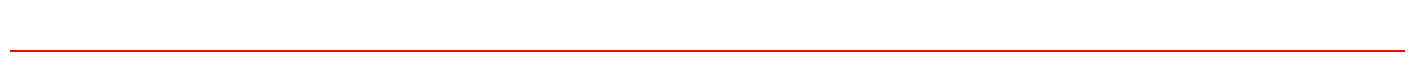

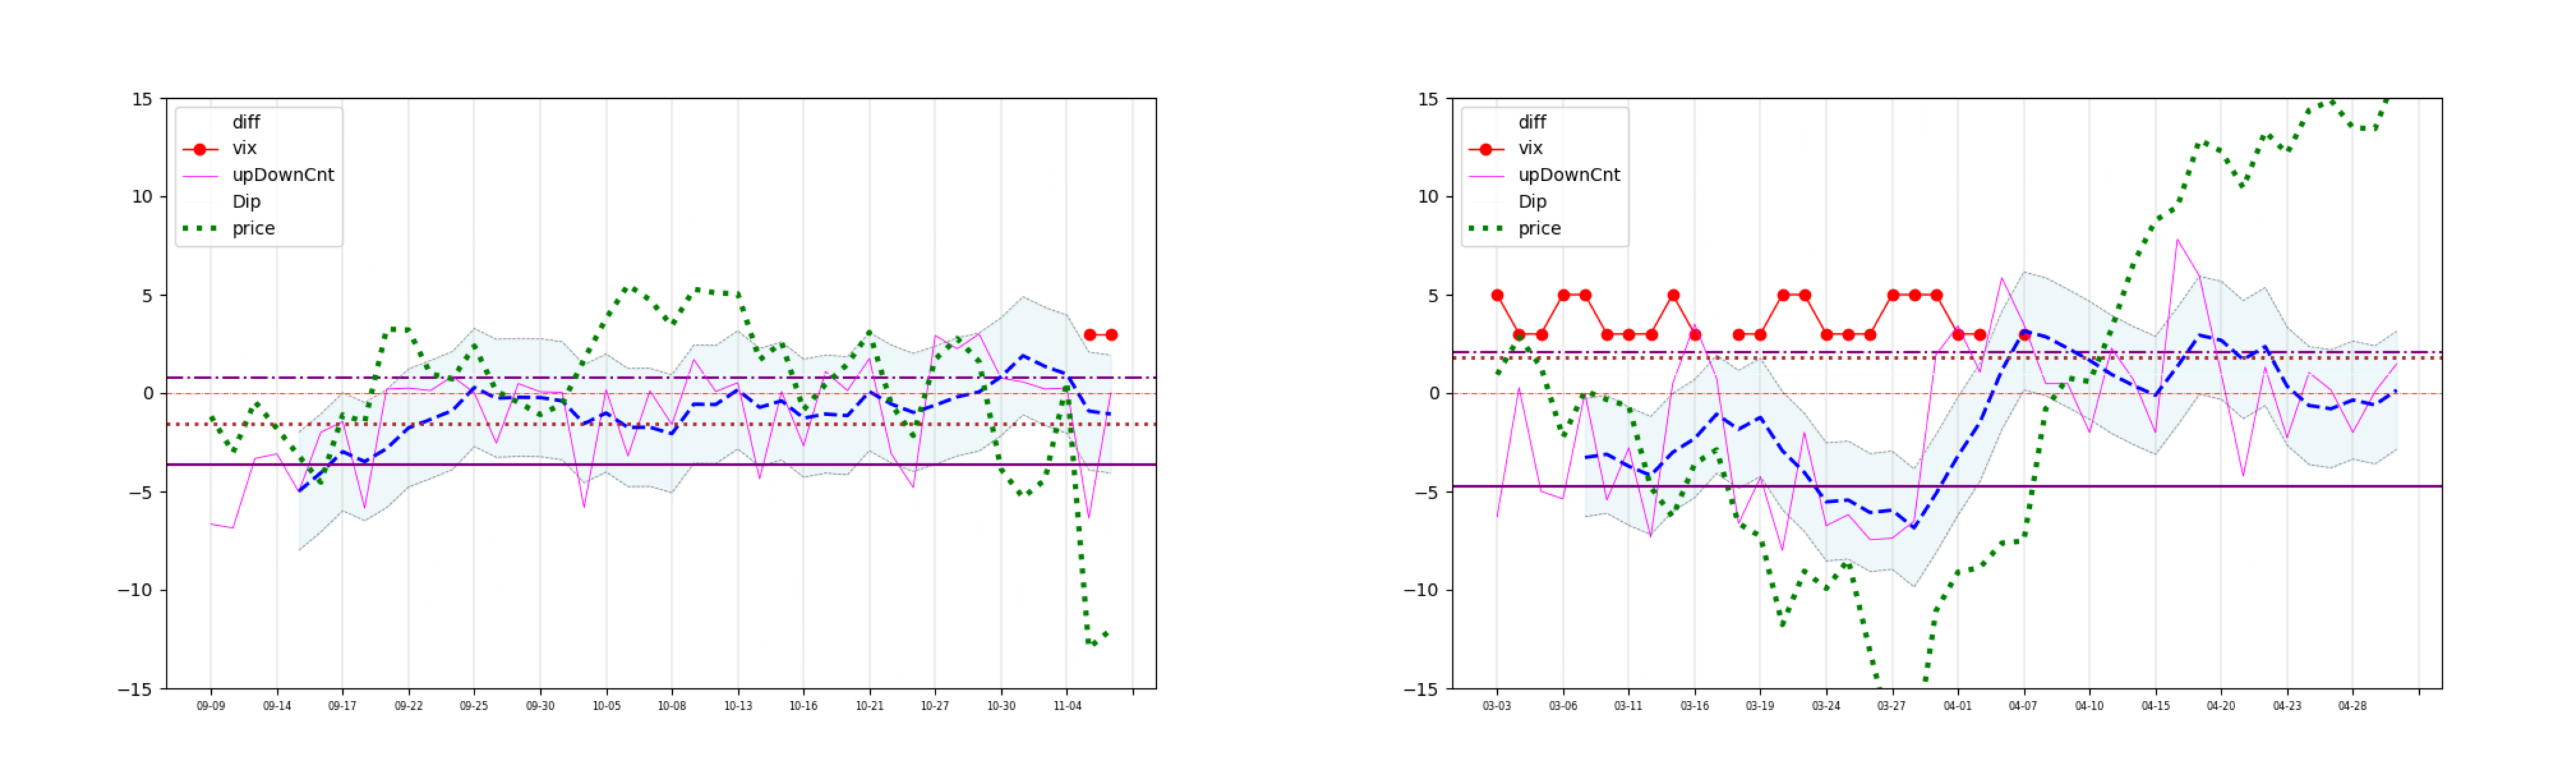

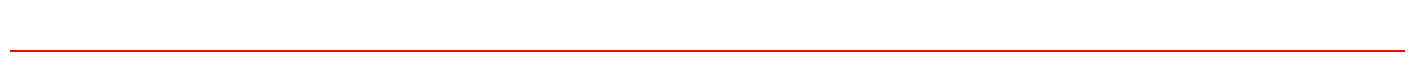

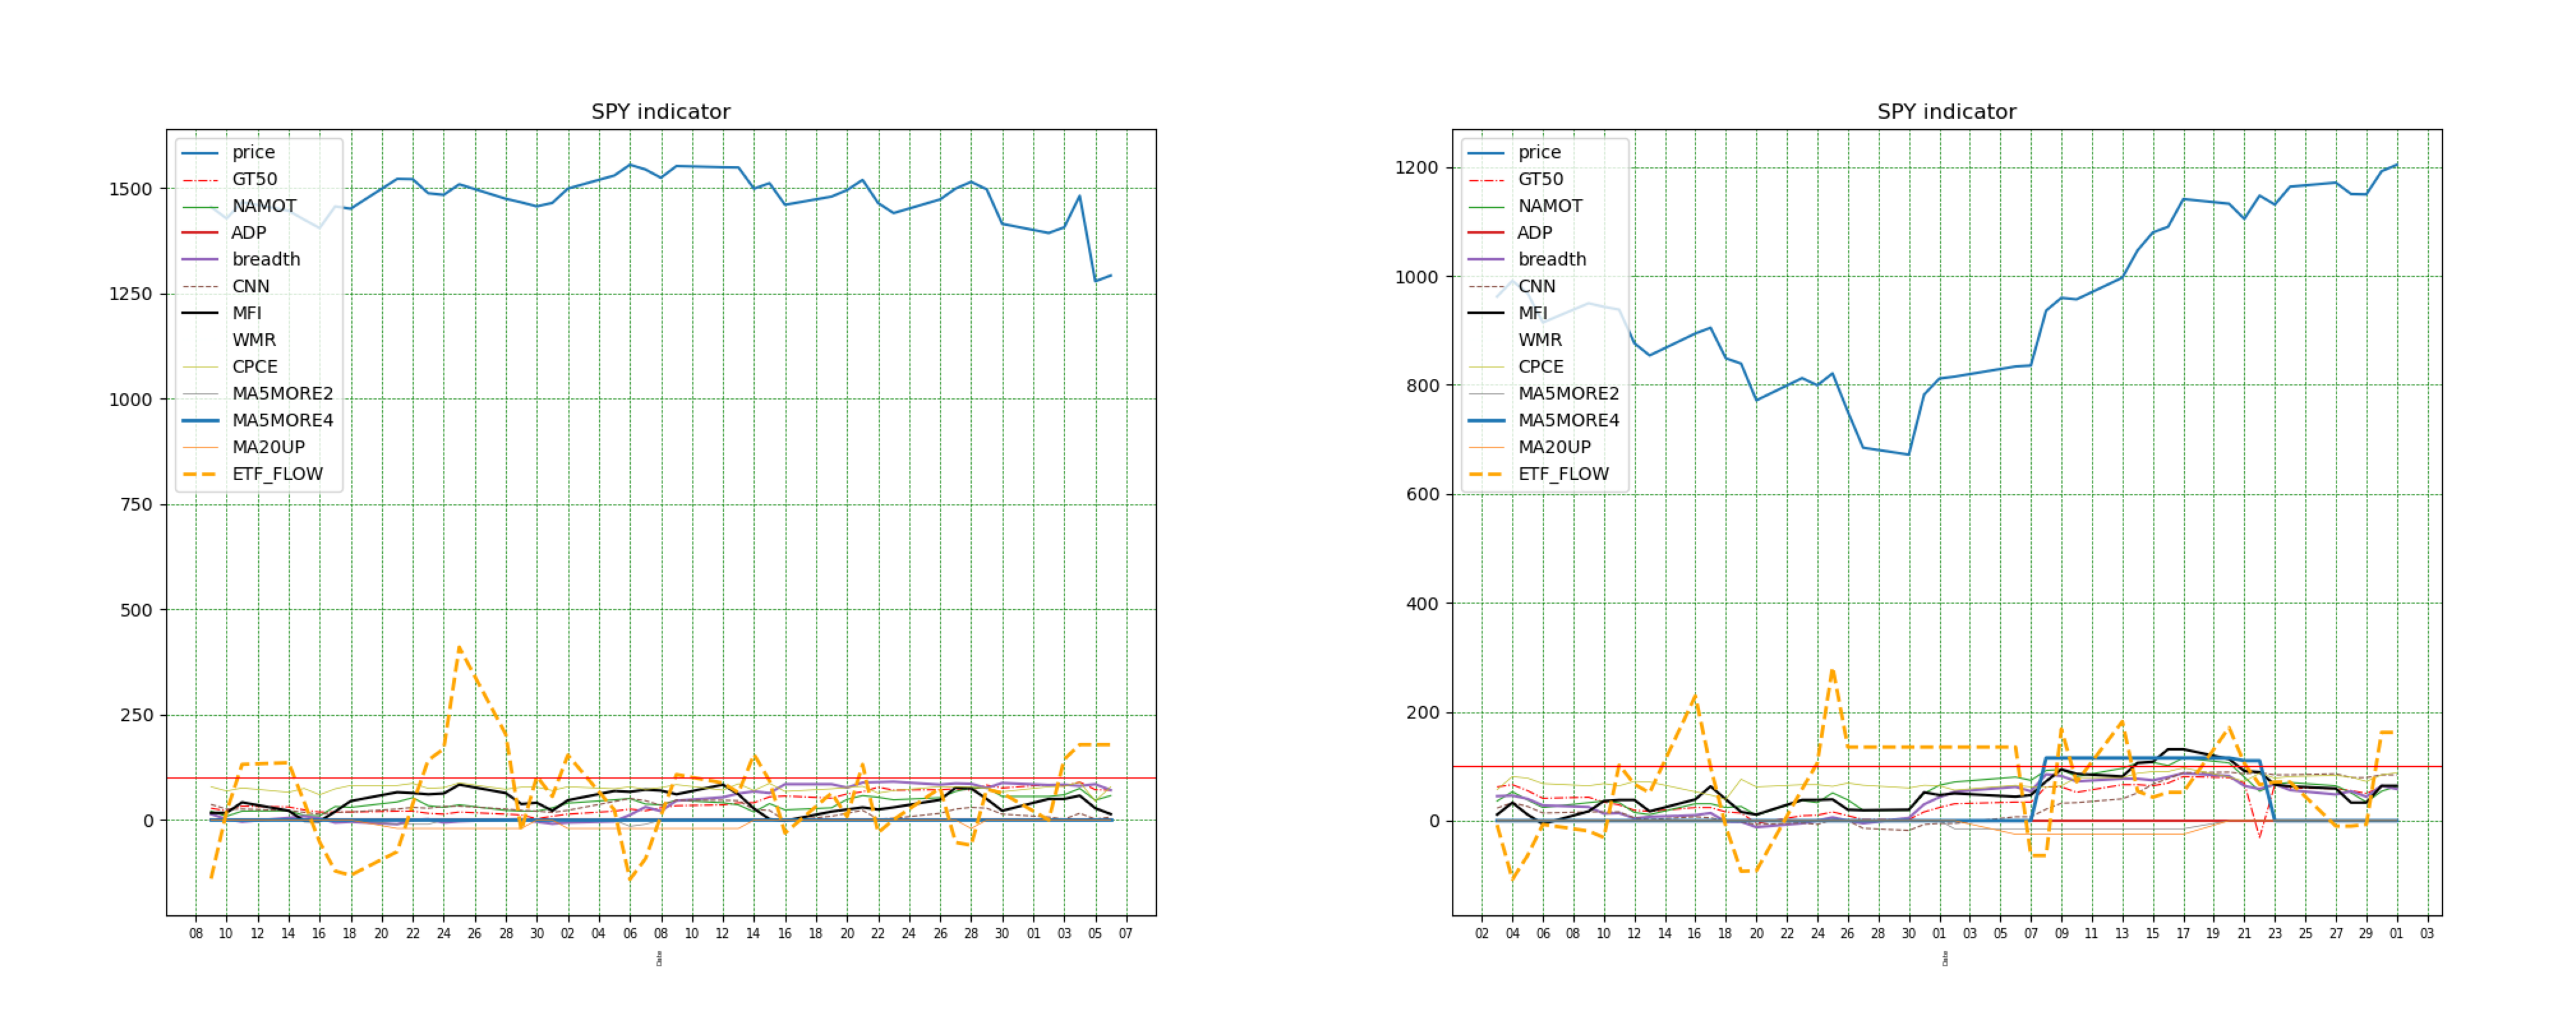

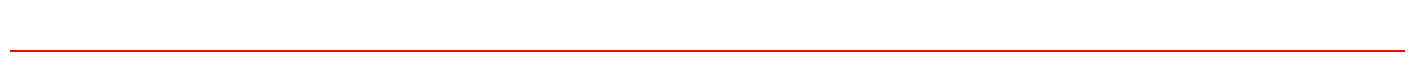

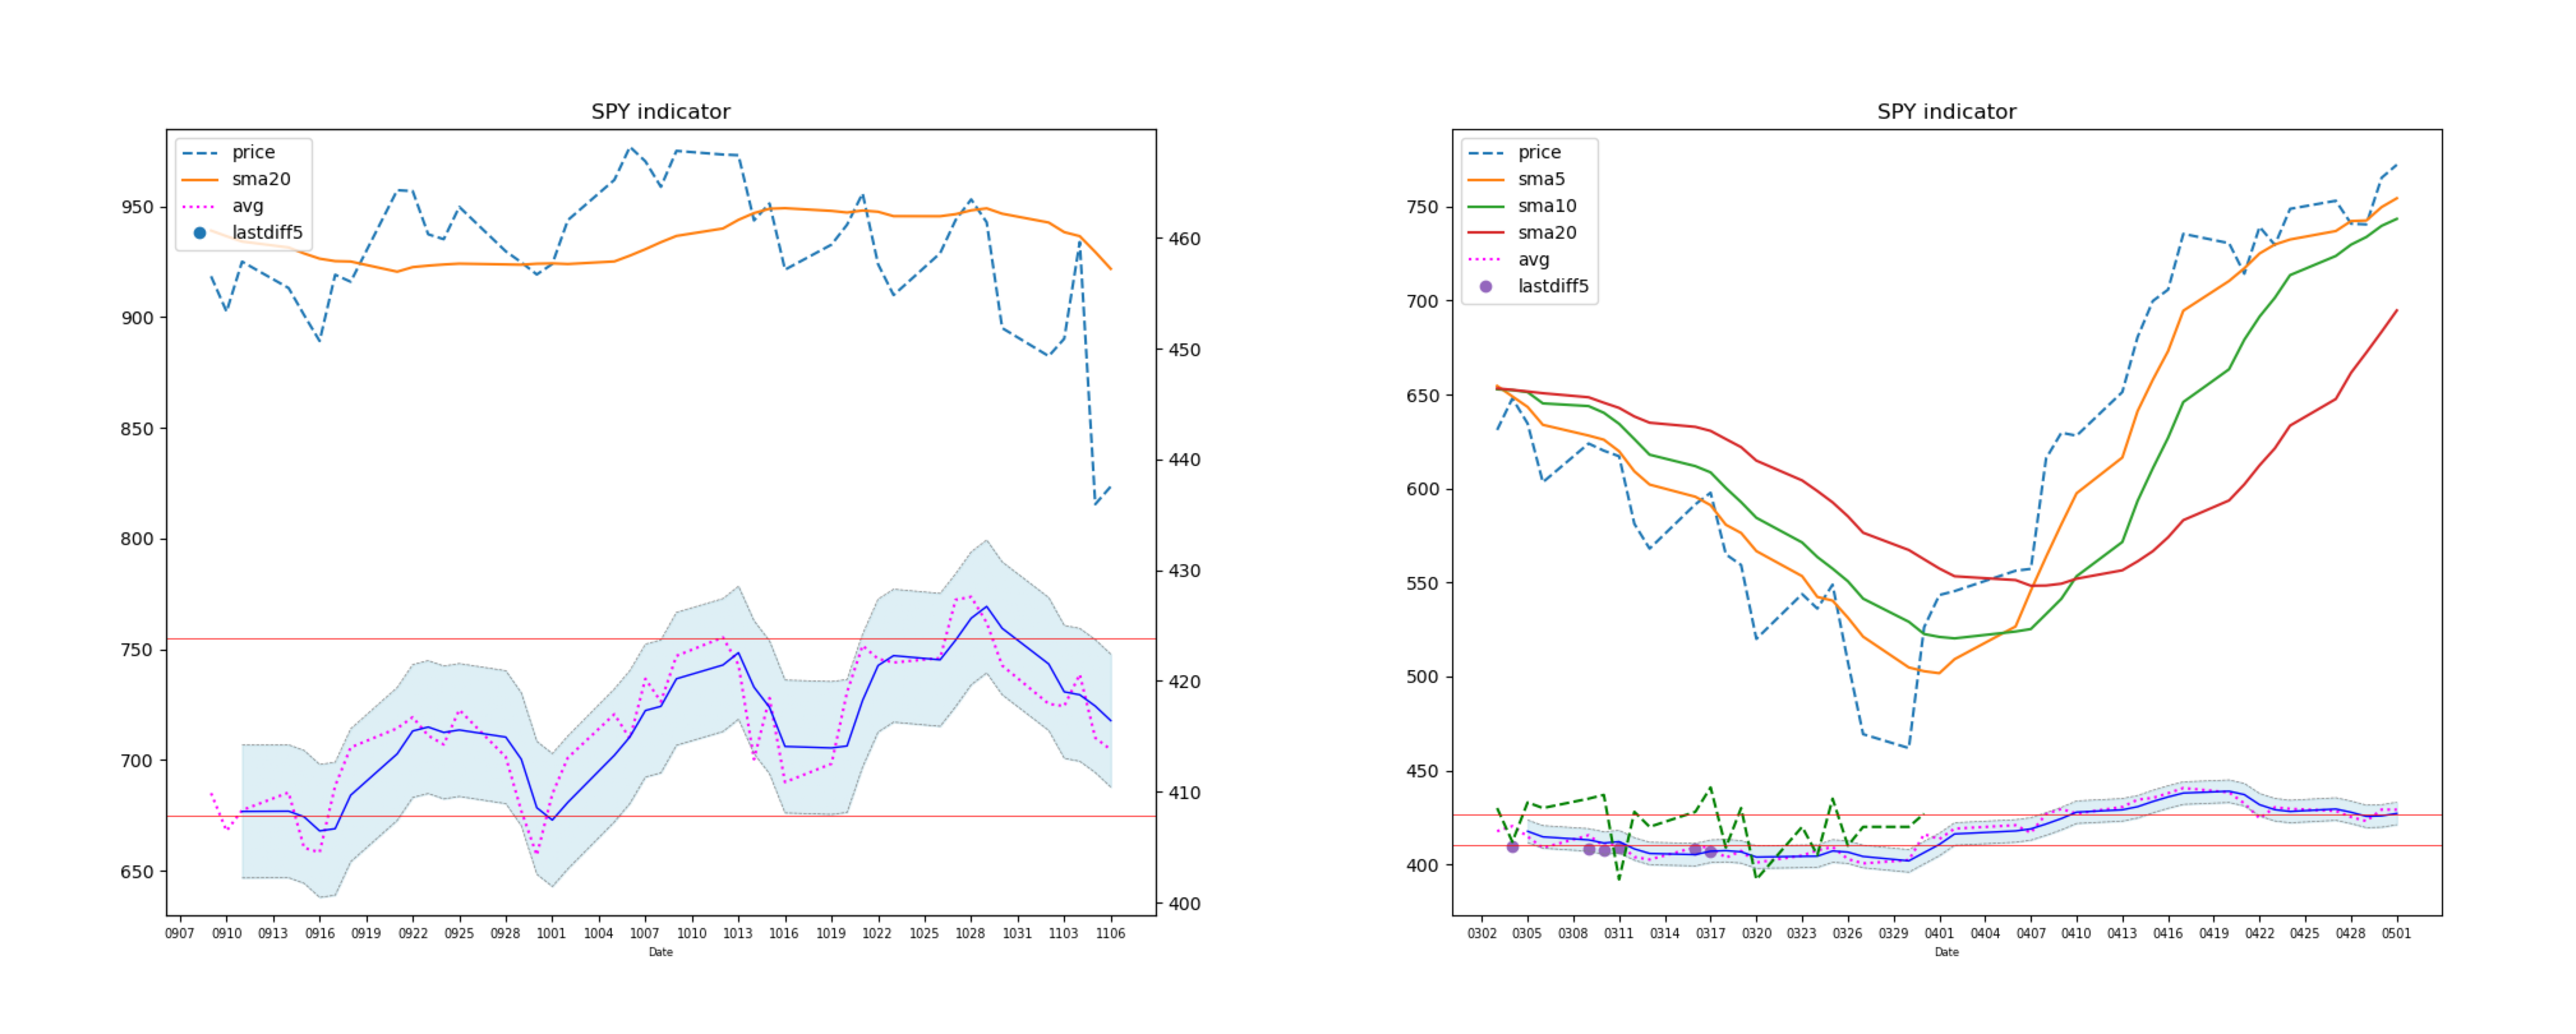

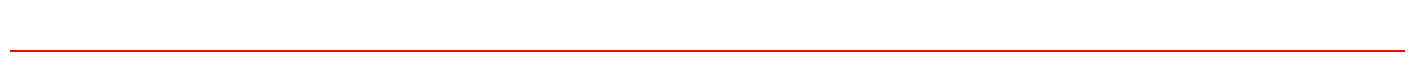

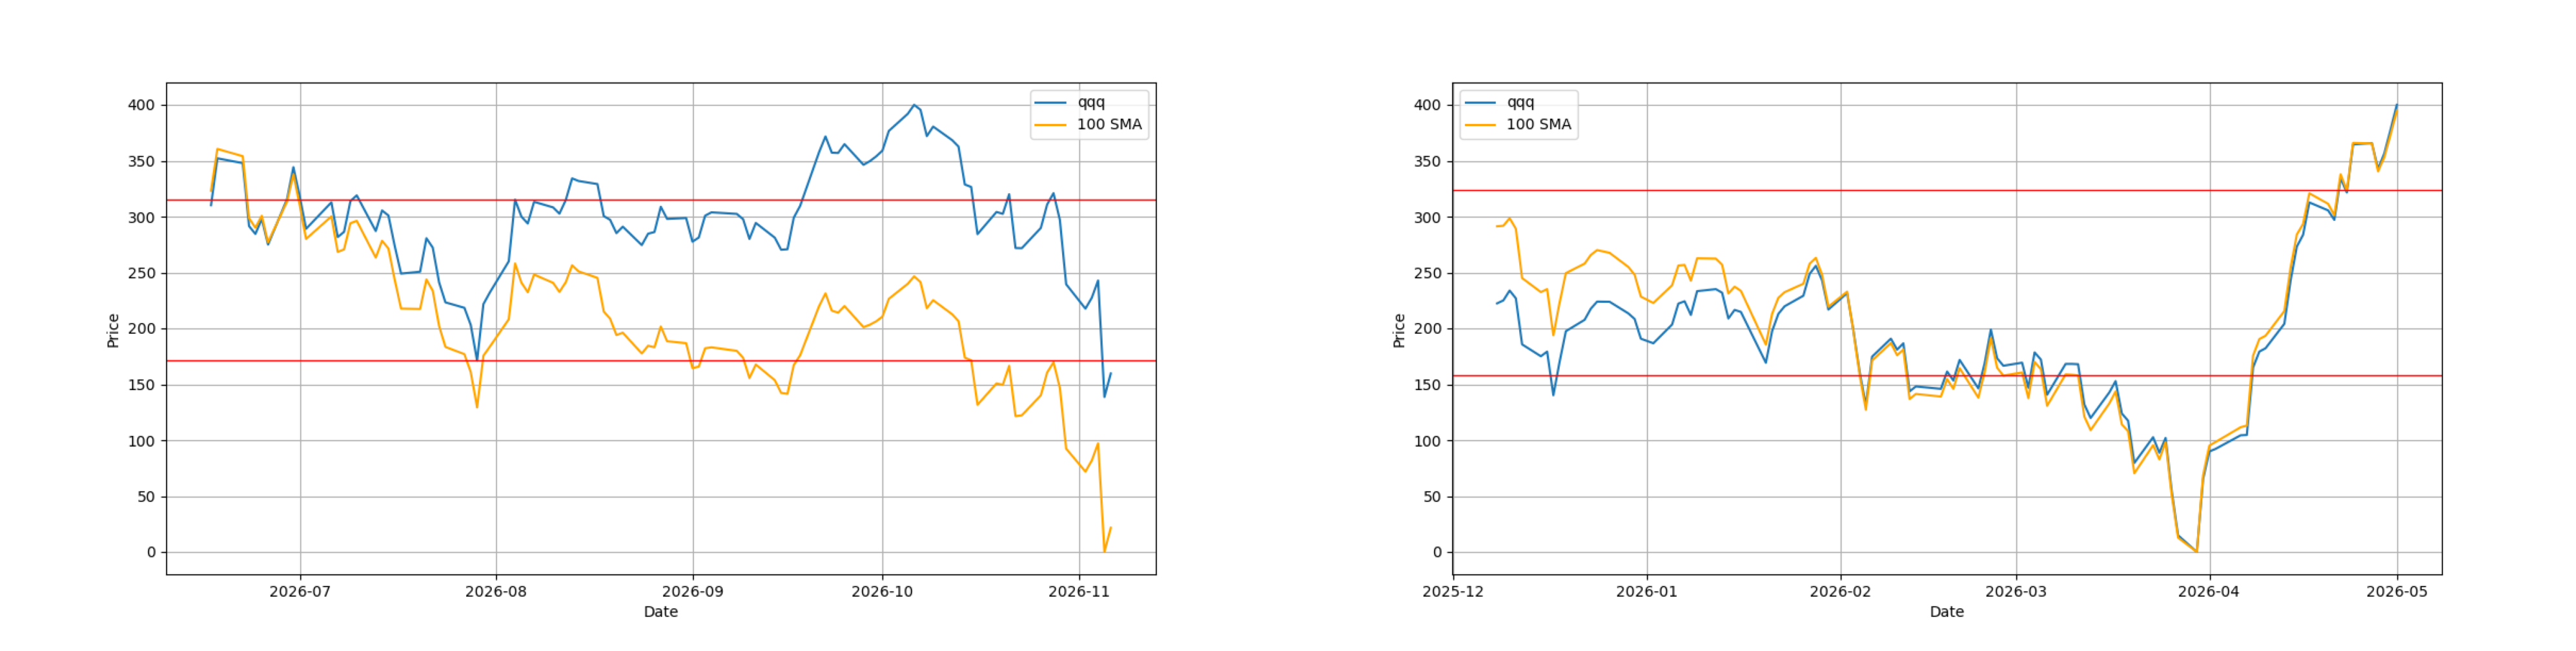

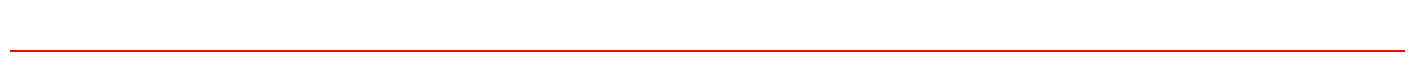

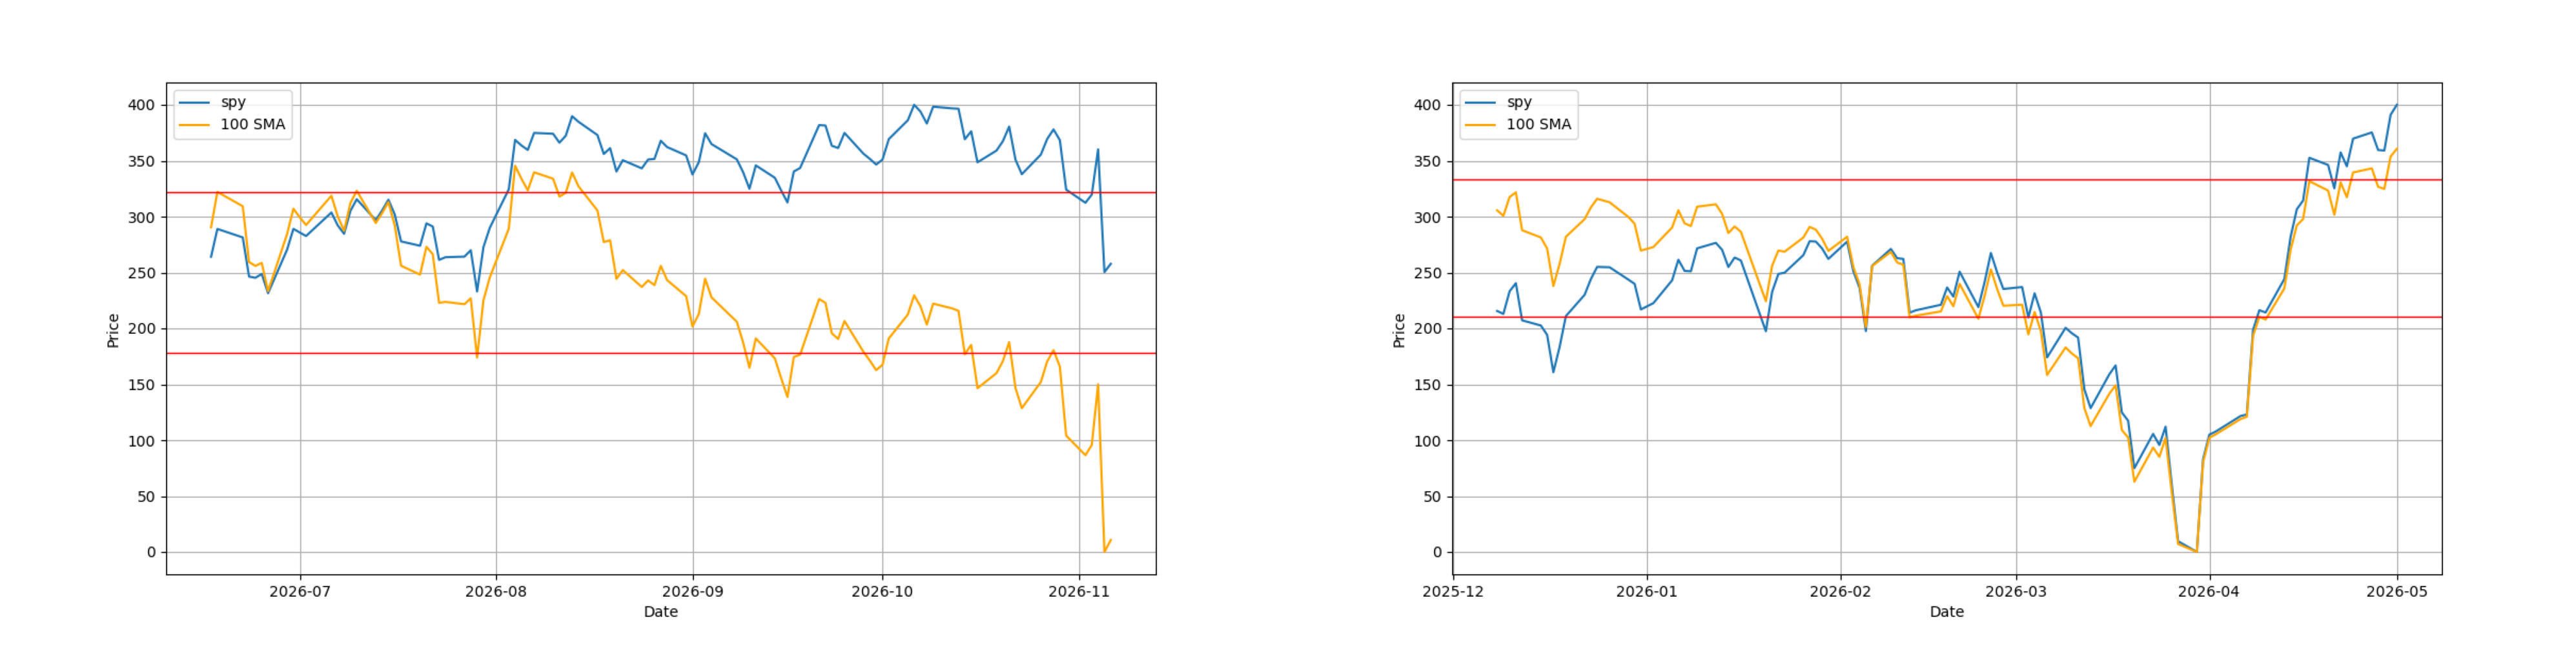

In [8]:


import os
from datetime import datetime, timedelta

def search_files(file_pattern, year, month):
    # List to hold the full paths of files that contain the search string
    matching_files = []
    
    folder_path = f"./{year}"

    # Walk through the directory
    for root, dirs, files in os.walk(folder_path):
        for file in files:
            if file_pattern in file and str(month) in file:
                # Append the full path of the matching file
                matching_files.append(os.path.join(root, file))
    
    return matching_files


def view_history_files(file_pattern, year, month):
    matching_files = search_files(file_pattern, year, month)
    if len(matching_files) == 0:
        return
#     print(matching_files[0])
    image2 = mpimg.imread(matching_files[0])
#     height2, width2 = image2.shape[0], image2.shape[1]
#     plt.rcParams["figure.figsize"] = (11.71, 15)
    plt.subplots_adjust(wspace=None, hspace=None)  
    fig, ax = plt.subplots(figsize=(20, 18)) 
    ax.set_title('')
    plt.title('')
    ax.imshow(image2)
    ax.axis('off')  # Turn off axes
#     ax2.imshow(image2[height2//2+20:, 98:])
#     ax2.imshow(image2[height2//3:, 98:], cmap='viridis')
    plt.tight_layout() 
    plt.show()
    
def view_two_history_files(image_path1, image_path2):
    
    draw_line()
    if  len(image_path1) > 0:
        image1 = mpimg.imread(image_path1[0])
    if  len(image_path2) > 0:
        image2 = mpimg.imread(image_path2[0])

    # Create a figure with two subplots
    fig, axes = plt.subplots(1, 2, figsize=(40, 30))

    # Display the first image
    if  len(image_path1) > 0:
        axes[0].imshow(image1)
    axes[0].axis('off')  # Turn off axes
    axes[0].set_title('')

    if  len(image_path2) > 0:
        # Display the second image
        axes[1].imshow(image2)
    axes[1].axis('off')  # Turn off axes
    axes[1].set_title('')

    plt.subplots_adjust(wspace=None, hspace=None)  
    plt.tight_layout() 
    # Show the plot
    plt.show()
    
def find_closest_divisible_by(number, mod_num):
    # Check if the specified number is already divisible by 3
    if number % mod_num == 0:
        return number
    # Find the closest number less than the specified number that is divisible by 3
    lower_number = number - (number % mod_num)
    return lower_number

def draw_line():
    # Create a new figure
    plt.figure(figsize=(18, 0.6))  # Width is set to 10, height is set to 1
    # Draw a horizontal line at y=0.5
    plt.axhline(y=0.1, color='r', linestyle='-')
    plt.axis('off')
    plt.title('')

    # Display the plot

def compare_files(file_pattern, year, month):
#     print(file_pattern)
    current_year = datetime.now().year
    current_month = datetime.now().month
    closed_month = find_closest_divisible_by(current_month, 3)    
    if closed_month == 0:
        closed_month = 1
#     print(f"{closed_month}")
    
#     matching_files_1 = search_files(file_pattern, current_year, closed_month)    
    matching_files_1 = [f"{file_pattern}.png"]
    matching_files_2 = search_files(file_pattern, year, month)
    
    view_two_history_files(matching_files_1, matching_files_2)
#     view_history_files(file_pattern, current_year, closed_month)
#     view_history_files(file_pattern, year, month)
    
old_year = 2026
old_month = 5

compare_files("indicator-cnt-updown", old_year, old_month)
compare_files("indicator-mrp", old_year, old_month)
compare_files("indicator-spy", old_year, old_month)
compare_files("indicator-pct-qqq", old_year, old_month)
compare_files("indicator-pct-spy", old_year, old_month)